In [1]:
# mostly relplotting hte old data but with the new models included in the plots now 

import pandas as pd 
pd.options.mode.chained_assignment = None  # default='warn'
import numpy as np 
import matplotlib.pyplot as plt 
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from matplotlib.markers import MarkerStyle
import seaborn as sns 
import pickle 
from sklearn import metrics 
import sys 
import scipy.stats
import glob
import copy
import time 
import json
from sklearn.metrics import auc, roc_curve, roc_auc_score

from config import (llm_review_path, home_path, supp_table_path, figure_path_2)

sys.path.insert(1, home_path)
from common_functions import sort_dict_by_value,format_p, mean_confidence_interval, entropy, sort_dict_by_key, my_colors

In [2]:
data_output_path = llm_review_path + "source_data_csvs/"

In [3]:

def p_val_to_stars(p):
    if p <= 0.001:
        return "***"
    if p <= 0.01:
        return "**"
    if p <= 0.05:
        return "*"
    return "ns"

# assumption is scores_1 is lower (more pathogenic)
def get_argmax_accuracy_point(scores_1, scores_2):
    maximum_val = max(np.max(scores_1), np.max(scores_2))
    minimum_val = min(np.min(scores_1), np.min(scores_2))
    argmax = None 
    max_accuracy = float("-inf")
    argmax_conf = []
    
    for cutoff in np.arange(minimum_val, maximum_val, 0.01):
        true_positives = np.sum(scores_2 > cutoff)
        false_negatives = np.sum(scores_2 <= cutoff)
        
        true_negatives = np.sum(scores_1 <= cutoff)
        false_postitives =  np.sum(scores_1 > cutoff)
        
        total_obs = true_positives + false_negatives + true_negatives + false_postitives
        accuracy = (true_positives + true_negatives) / total_obs
        
        if accuracy > max_accuracy:
            max_accuracy = accuracy
            argmax = cutoff
            argmax_conf = [[true_positives, false_postitives], [false_negatives, true_negatives]]
    
    return max_accuracy, argmax, argmax_conf


In [4]:
model_to_display_name = {
    "progen2_large" : "Progen2 (L)", 
    "progen2_medium" : "Progen2 (M)",
    "progen2_bfd" : "Progen2 (L) BFD", 
    "protbert_bfd":"ProtBERT BFD", 
    "prott5_xl" : "ProtT5-XL UR50",
    "prott5_xl_bfd": "ProtT5-XL BFD",
    "carp_600k": "CARP 600k",
    "carp_38M": "CARP 38M",
    "carp_76M": "CARP 76M",
    "carp_640M": "CARP 640M",
}

In [5]:
res_path = "../../../revisions/scripts/human_proteome_short/results/"


model_list = [
    "progen2_large", 
    "progen2_medium", 
    "progen2_bfd", 
    "prott5_xl",
    "carp_38M",
    "carp_76M",
    "carp_640M"
]


model_to_data = {}

for m in model_list:
    t1 = time.time()
    print(m)
    fn = res_path + "summary_stats_" + m + ".pkl"

    with open(fn , "rb") as f1:
        data = pickle.load(f1)
    f1.close()
    
    model_to_data[m] = data
    
    t2 = time.time()
    
    print(t2 - t1)

progen2_large
62.35310649871826
progen2_medium
61.48793387413025
progen2_bfd
66.30356287956238
prott5_xl
72.08042860031128
carp_38M
75.951495885849
carp_76M
76.74093079566956
carp_640M
78.13266777992249


In [6]:

model_to_pos_to_site_entropy_list = {}

for m, data in model_to_data.items():
    pos_to_site_entropy_list = {}
    for gene_name, v in data.items():
        site_ent_dict = v["site_entropy"]
            
        for pos, ent_val in site_ent_dict.items():
            if ent_val < 0:
                continue
            if pos in pos_to_site_entropy_list.keys():
                pos_to_site_entropy_list[pos].append(ent_val)
            else:
                pos_to_site_entropy_list[pos] = [ent_val]
    model_to_pos_to_site_entropy_list[m] = pos_to_site_entropy_list




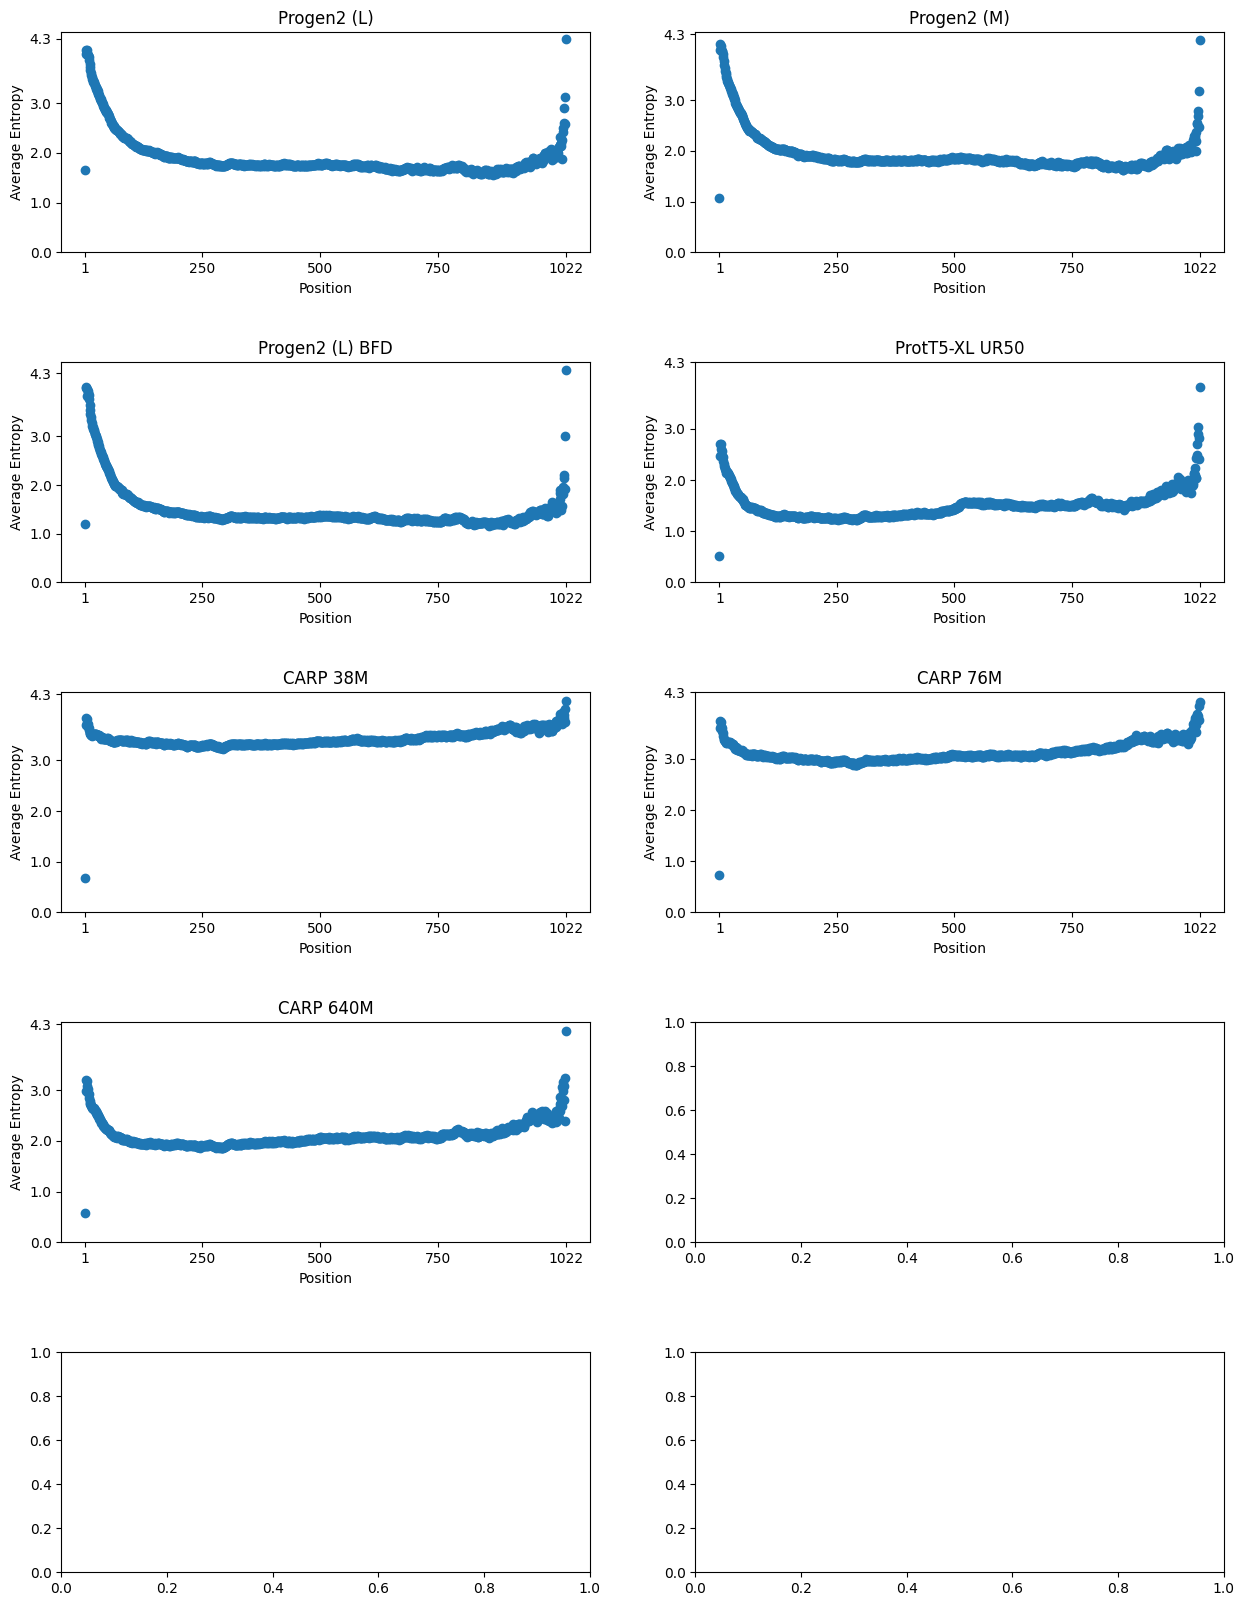

In [7]:
fig, axes = plt.subplots(5, 2, figsize = (15, 20))
axes = axes.ravel()
fig.subplots_adjust(hspace = 0.5)

for i , (m , pos_to_site_entropy_list) in enumerate(model_to_pos_to_site_entropy_list.items()):
    ax = axes[i]
    positions = []
    average_entropy = []

    for k, v in pos_to_site_entropy_list.items():
        positions.append(k)
        average_entropy.append(np.mean(v))


    ax.scatter(positions, average_entropy)
    ax.set_title(m)
    
    ax.set_yticks([0, 1, 2, 3, 4.3])
    ax.set_xticks([1,250,500,750,1022])
    
    ax.set_ylabel("Average Entropy")
    ax.set_xlabel("Position")
    
    ax.set_title(model_to_display_name[m])
    
    
    
    

In [8]:
pd.read_csv(supp_table_path  + "positional_entropies_1_through_1000_tiled_and_rotary.csv")
 

,Unnamed: 0,Model,aa_position,mean_positional_entropy_length_1000_to_1022,mean_positional_entropy_proteins_length_2000_to_3000_rotary,mean_positional_entropy_proteins_length_3000_to_4000_rotary,mean_positional_entropy_proteins_length_2000_to_3000_tiled,mean_positional_entropy_proteins_length_3000_to_4000_tiled
0,1,ESM-2 (8M),1,0.789801,3.999811,3.994968,1.107137,1.200607
1,2,ESM-2 (8M),2,3.744782,4.002767,3.983282,3.811514,3.822419
2,3,ESM-2 (8M),3,3.897910,4.004611,3.976732,3.907046,3.904177
3,4,ESM-2 (8M),4,3.900433,3.996079,3.954376,3.887638,3.900341
4,5,ESM-2 (8M),5,3.839739,3.992754,3.970503,3.872150,3.874380
...,...,...,...,...,...,...,...,...
5995,996,ESM-2 (15B),996,1.484521,1.728287,1.480490,1.681845,1.442077
5996,997,ESM-2 (15B),997,1.574059,1.670847,1.715363,1.631921,1.497031
5997,998,ESM-2 (15B),998,1.659087,1.690295,1.425301,1.641682,1.330408
5998,999,ESM-2 (15B),999,1.636353,1.688587,1.503213,1.642327,1.343716


In [9]:
needed_variants_df = pd.read_csv(f"{llm_review_path}figure_panels/submission/table_csvs/clinvar_misclassification_all_models_all_variants.csv")
needed_variants_df = needed_variants_df.loc[needed_variants_df["model"] == "ESM-2 (3B)"] # can be any model, all are the same re: variants listed which is all I need here 

long_variants = needed_variants_df.loc[needed_variants_df["is_long_protein"]]
short_variants = needed_variants_df.loc[~needed_variants_df["is_long_protein"]]


long_variants_train = long_variants.loc[long_variants["train_test_split"] == "Train"]
long_variants_test = long_variants.loc[long_variants["train_test_split"] == "Test"]
short_variants_train = short_variants.loc[short_variants["train_test_split"] == "Train"]
short_variants_test = short_variants.loc[short_variants["train_test_split"] == "Test"]

print(len(long_variants_train), len(long_variants_test), len(short_variants_train), len(short_variants_test))

1830 1840 3310 3310


In [10]:
wanted_model = "carp_640M"

model_data = model_to_data[wanted_model]

found = 0 
not_found = 0

short_variants_scores = {}

for index, row in short_variants.iterrows():
    score = model_data[row["gene_name"]]["scores"][row["name"]]
    short_variants_scores[row["full_name"]] = score

In [11]:
long_score_path = f"../../../revisions/data/new_models/human_proteome_long_tiled_combined_csvs/{wanted_model}/"

t1 = time.time()

long_variants_tiled_scores = {}

for g, sub_df in long_variants.groupby("gene_name"):
    df = pd.read_csv(long_score_path + g + ".csv.gz")
    variant_to_score = dict(zip(df["name"].values, df["weighted_score"].values))
    for index, row in sub_df.iterrows():
        v_name = g + "_" + row["name"]
        long_variants_tiled_scores[v_name] = variant_to_score[row["name"]]
    
t2 = time.time()

print(t2 - t1)

/tmp/ipykernel_1962772/1313872127.py:8: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + g + ".csv.gz")
/tmp/ipykernel_1962772/1313872127.py:8: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + g + ".csv.gz")
/tmp/ipykernel_1962772/1313872127.py:8: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + g + ".csv.gz")
/tmp/ipykernel_1962772/1313872127.py:8: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + g + ".csv.gz")
/tmp/ipykernel_1962772/1313872127.py:8: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + g + "

80.57453322410583


MannwhitneyuResult(statistic=3021613.0, pvalue=0.6179242129456815)
MannwhitneyuResult(statistic=3158771.0, pvalue=0.008482993421214991)
MannwhitneyuResult(statistic=2964674.0, pvalue=0.9215680041272228)


Text(0.5, 1.0, 'CARP 640M')

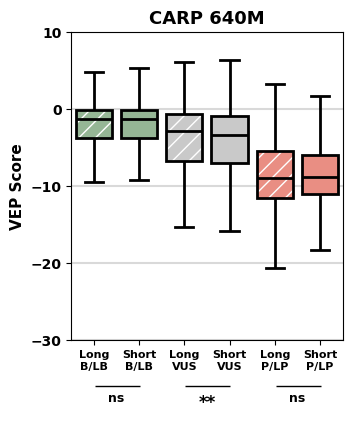

In [12]:
short_variants_plp_scores = []
short_variants_blb_scores = []
short_variants_vus_scores = []

long_variants_plp_scores = []
long_variants_blb_scores = []
long_variants_vus_scores = []


all_vus = set(needed_variants_df.loc[needed_variants_df["clinvar_annotation"] == "VUS"]["full_name"].values)
all_plp = set(needed_variants_df.loc[needed_variants_df["clinvar_annotation"] == "PLP"]["full_name"].values)
all_blb = set(needed_variants_df.loc[needed_variants_df["clinvar_annotation"] == "BLB"]["full_name"].values)


for k, v in  long_variants_tiled_scores.items():
    if k in all_vus:
        long_variants_vus_scores.append(v)
    elif k in all_plp:
        long_variants_plp_scores.append(v)
    elif k in all_blb:
        long_variants_blb_scores.append(v)
        
for k, v in  short_variants_scores.items():
    if k in all_vus:
        short_variants_vus_scores.append(v)
    elif k in all_plp:
        short_variants_plp_scores.append(v)
    elif k in all_blb:
        short_variants_blb_scores.append(v)
        
        
fig, ax = plt.subplots(figsize = (3.5,4))

data = [long_variants_blb_scores, short_variants_blb_scores , long_variants_vus_scores, short_variants_vus_scores, long_variants_plp_scores, short_variants_plp_scores]


my_pal = {
    0 : "darkseagreen", 
    1 : "darkseagreen", 
    2 : "#c9c9c9", 
    3 : "#c9c9c9", 
    4 : "salmon", 
    5 : "salmon"
}


ax = sns.boxplot(
    data,
    palette = my_pal,
    showfliers = False,
    boxprops=dict(linewidth=2, edgecolor='black', zorder = 100),
    medianprops=dict(linewidth=2, color='black', zorder = 100),
    whiskerprops=dict(linewidth=2, color='black', zorder = 100),
    capprops = dict(linewidth=2, color='black', zorder = 100),
    ax = ax
)

print(scipy.stats.mannwhitneyu(data[0], data[1], alternative = "greater"))
print(scipy.stats.mannwhitneyu(data[2], data[3], alternative = "greater"))
print(scipy.stats.mannwhitneyu(data[4], data[5], alternative = "greater"))

patches = [patch for patch in ax.patches if type(patch) == mpatches.PathPatch]
   
hatch_list = ["//", "", "//", "", "//", ""]
for patch, hatch in zip(patches, hatch_list):
    patch.set_hatch(hatch)

hatch_colors = ["white", "gray", "white", "gray", "white", "gray"]
for i, patch in enumerate(ax.patches):
    patch._hatch_color = mcolors.to_rgba(hatch_colors[i])


ax.set_yticks([-30, -20, -10, 0, 10])
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")

for y_val in ax.get_yticks():
    ax.axhline(y = y_val, color = "black", alpha = 0.15, zorder = 1)

ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(
    [
        "Long\nB/LB",
        "Short\nB/LB",
#         "",
        "Long\nVUS",
        "Short\nVUS",
#         "",
        "Long\nP/LP",
        "Short\nP/LP",
    ],
    fontsize = 8,
    fontweight = "bold"
)

rect1 = mpatches.Rectangle(((1/6)-0.08, -0.15), 1/6, 0.002,  transform = ax.transAxes, clip_on = False, color = "black")
rect2 = mpatches.Rectangle((3/6-0.08, -0.15), 1/6, 0.002, transform = ax.transAxes,clip_on = False, color = "black")
rect3 = mpatches.Rectangle((5/6-0.08, -0.15), 1/6, 0.002,transform = ax.transAxes, clip_on = False, color = "black")
ax.add_patch(rect1)
ax.add_patch(rect2)
ax.add_patch(rect3)

st, p = scipy.stats.mannwhitneyu(long_variants_blb_scores, short_variants_blb_scores , alternative = "greater")
p_str = format_p(p)
p_stars = p_val_to_stars(p)
ax.text(1/6,  -0.2 if p_stars == "ns" else -0.22, p_stars , transform = ax.transAxes, horizontalalignment = "center", fontsize = 9 if p_stars == "ns" else 12, fontweight = "bold")

st, p = scipy.stats.mannwhitneyu(long_variants_vus_scores, short_variants_vus_scores , alternative = "greater")
p_str = format_p(p)

p_stars = p_val_to_stars(p)
ax.text(3/6,  -0.2 if p_stars == "ns" else -0.22, p_stars, transform = ax.transAxes, horizontalalignment = "center", fontsize = 9 if p_stars == "ns" else 12, fontweight = "bold")


st, p = scipy.stats.mannwhitneyu(long_variants_plp_scores, short_variants_plp_scores, alternative = "greater")
p_stars = p_val_to_stars(p)
ax.text(5/6,  -0.2 if p_stars == "ns" else -0.22, p_stars, transform = ax.transAxes, horizontalalignment = "center", fontsize = 9 if p_stars == "ns" else 12, fontweight = "bold")

ax.set_ylabel("VEP Score", fontsize = 11, fontweight = "bold")
ax.set_title(model_to_display_name[wanted_model], fontsize = 13, fontweight = "bold")


915 920 915 920
1655 1655 1655 1655
0.8143968871595331 -5.390947864334212


Text(0.03, 0.9, 'Acc = 81.44%')

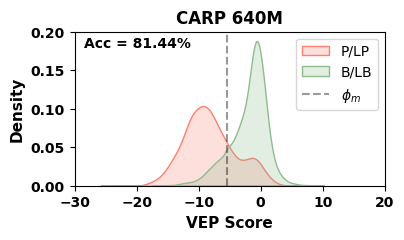

In [13]:

all_train = set(needed_variants_df.loc[needed_variants_df["train_test_split"] == "Train"]["full_name"].values)
all_test = set(needed_variants_df.loc[needed_variants_df["train_test_split"] == "Test"]["full_name"].values)


all_vus = set(needed_variants_df.loc[needed_variants_df["clinvar_annotation"] == "VUS"]["full_name"].values)
all_plp = set(needed_variants_df.loc[needed_variants_df["clinvar_annotation"] == "PLP"]["full_name"].values)
all_blb = set(needed_variants_df.loc[needed_variants_df["clinvar_annotation"] == "BLB"]["full_name"].values)


train_plp_long = []
train_plp_short = []
train_blb_long = []
train_blb_short = []

test_plp_long = []
test_plp_short = []
test_blb_short = []
test_blb_long = []



for k, v in  short_variants_scores.items():
    if k in all_plp:
        if k in all_train:
            train_plp_short.append(v)
        
        elif k in all_test:
            test_plp_short.append(v)
    
    elif k in all_blb:
        if k in all_train:
            train_blb_short.append(v)
        elif k in all_test:
            test_blb_short.append(v)
            
 
for k, v in  long_variants_tiled_scores.items():
    if k in all_plp:
        if k in all_train:
            train_plp_long.append(v)
        
        elif k in all_test:
            test_plp_long.append(v)
    
    elif k in all_blb:
        if k in all_train:
            train_blb_long.append(v)
        elif k in all_test:
            test_blb_long.append(v)
            
            

print(len(train_plp_long), len(test_plp_long), len(train_blb_long), len(test_blb_long))
print(len(train_plp_short), len(test_plp_short), len(train_blb_short), len(test_blb_short))


all_train_plp = train_plp_long + train_plp_short
all_train_blb = train_blb_long + train_blb_short

max_accuracy, argmax_acc, argmax_conf = get_argmax_accuracy_point(all_train_plp, all_train_blb)

print(max_accuracy, argmax_acc)

fig, ax = plt.subplots(figsize = (4,2))


sns.kdeplot(all_train_plp, ax = ax, fill = True, color = "salmon", label = "P/LP")
sns.kdeplot(all_train_blb, ax = ax, fill = True, color = "darkseagreen", label = "B/LB")



ax.set_xlabel("VEP Score", fontsize = 11, fontweight = "bold")
ax.set_title(model_to_display_name[wanted_model], fontsize = 12, fontweight = "bold")
ax.set_ylabel("Density", fontsize = 11, fontweight = "bold")
ax.set_yticks(ax.get_yticks())
ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(ax.get_xticklabels(), fontweight = "bold")
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")

ax.axvline(x = argmax_acc, linestyle = "--", color = "black", alpha = 0.4,label = "$\phi_m$")
ax.legend(loc = "upper right")

acc_str = str(round(max_accuracy * 100, 2)) + "%"

# if model == "esm_2_15B":
#     ax.text(0.61, 0.15, "Acc = " + acc_str, transform = ax.transAxes, fontweight = "bold")
# else:
ax.text(0.03, 0.9, "Acc = " + acc_str, transform = ax.transAxes, fontweight = "bold")


0.7987915407854985 0.2012084592145015
0.7510869565217392 0.24891304347826088


Text(0.5, 1.0, 'CARP 640M')

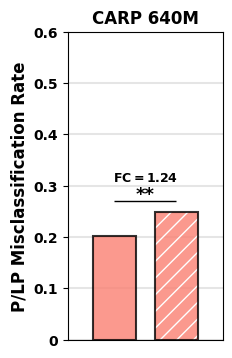

In [14]:
plp_correct_short = len(list(filter(lambda x : x <= argmax_acc, test_plp_short)))
plp_incorrect_short = len(list(filter(lambda x : x >  argmax_acc, test_plp_short)))

print(plp_correct_short / len(test_plp_short), plp_incorrect_short / len(test_plp_short))

plp_correct_long = len(list(filter(lambda x : x <= argmax_acc, test_plp_long)))
plp_incorrect_long = len(list(filter(lambda x : x > argmax_acc, test_plp_long)))

print(plp_correct_long / len(test_plp_long), plp_incorrect_long / len(test_plp_long))


table_plp = [
    [plp_correct_long, plp_incorrect_long],
    [plp_correct_short, plp_incorrect_short]
]

p  = scipy.stats.chi2_contingency(table_plp)[1]

stars = p_val_to_stars(p)



fig, ax = plt.subplots(figsize = (2,4))

misclass_rate_short = plp_incorrect_short / (plp_incorrect_short + plp_correct_short)
misclass_rate_long = plp_incorrect_long / (plp_incorrect_long + plp_correct_long)
ax.bar(
    [0,1], 
    [misclass_rate_short, misclass_rate_long], 
    width = 0.7, 
    color = "salmon", 
    edgecolor = "black", 
    alpha = 0.8, 
    linewidth = 1.5, 
    zorder = 100
)
ax.set_ylim(bottom = 0)

hatch_list = ["", "//"]
patches = ax.patches
for patch, hatch in zip(patches, hatch_list):
    patch.set_hatch(hatch)
    patch._hatch_color = mcolors.to_rgba("white")

ax.tick_params(
    axis='x',          # changes apply to the x-axis
    which='both',      # both major and minor ticks are affected
    bottom=False,      # ticks along the bottom edge are off
    top=False,         # ticks along the top edge are off
    labelbottom=False
) 
# misclass_rate_short
ax.set_ylabel("P/LP Misclassification Rate", fontsize = 12, fontweight = "bold")
ax.set_ylim(bottom = 0, top = 0.6)
ax.set_yticks([0,0.1,0.2,0.3,0.4,0.5,0.6])
ax.set_yticklabels([0,0.1,0.2,0.3,0.4,0.5,0.6], fontweight = "bold")
for y_val in ax.get_yticks():
    ax.axhline(y = y_val, alpha = 0.1, color = "black", zorder = 1)

# ax.set_xticks([0,1])
# ax.set_xticklabels(["Short", "Long"])

ax.set_xlim(left = -0.75, right = 1.75)
hatch_list = ["", "//"]
patches = ax.patches
for patch, hatch in zip(patches, hatch_list):
    patch.set_hatch(hatch)
    patch._hatch_color = mcolors.to_rgba("white")
    
val = 0

y_bar_pos = np.max([misclass_rate_short, misclass_rate_long]) + 0.02

rect = mpatches.Rectangle((val , y_bar_pos), 1., 0.0005, clip_on = False, color = "black")
ax.add_patch(rect)

fc = misclass_rate_long / misclass_rate_short

ax.text(val + 0.5, y_bar_pos + 0.005, stars, fontweight = "bold", horizontalalignment = "center", fontsize = 13)
ax.text(val + 0.5, y_bar_pos+ 0.04, "$\mathbf{FC=" + str(round(fc, 2)) + "}$", fontweight = "bold", horizontalalignment = "center",  fontsize = 9)

ax.set_title(model_to_display_name[wanted_model], fontweight = "bold")

Text(0.5, 1.0, 'CARP 640M')

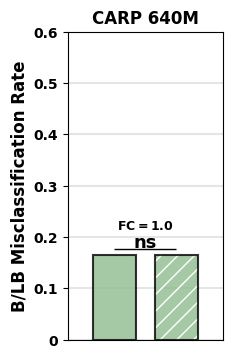

In [15]:
blb_correct_short = len(list(filter(lambda x : x > argmax_acc, test_blb_short)))
blb_incorrect_short = len(list(filter(lambda x : x <=  argmax_acc, test_blb_short)))

# print(plp_correct_short / len(test_plp_short), plp_incorrect_short / len(test_plp_short))

blb_correct_long = len(list(filter(lambda x : x > argmax_acc, test_blb_long)))
blb_incorrect_long = len(list(filter(lambda x : x <= argmax_acc, test_blb_long)))

# print(plp_correct_long / len(test_plp_long), plp_incorrect_long / len(test_plp_long))


table_blb = [
    [blb_correct_long, blb_incorrect_long],
    [blb_correct_short, blb_incorrect_short]
]

p  = scipy.stats.chi2_contingency(table_blb)[1]

stars = p_val_to_stars(p)
misclass_rate_short = blb_incorrect_short / (blb_incorrect_short + blb_correct_short)
misclass_rate_long = blb_incorrect_long / (blb_incorrect_long + blb_correct_long)

fc = misclass_rate_long / misclass_rate_short

fig, ax = plt.subplots(figsize = (2,4))



ax.bar(
    [0,1], 
    [misclass_rate_short, misclass_rate_long], 
    width = 0.7, 
    color = "darkseagreen", 
    edgecolor = "black", 
    alpha = 0.8, 
    linewidth = 1.5, 
    zorder = 100
)
ax.set_ylim(bottom = 0)

hatch_list = ["", "//"]
patches = ax.patches
for patch, hatch in zip(patches, hatch_list):
    patch.set_hatch(hatch)
    patch._hatch_color = mcolors.to_rgba("white")

ax.tick_params(
    axis='x',          # changes apply to the x-axis
    which='both',      # both major and minor ticks are affected
    bottom=False,      # ticks along the bottom edge are off
    top=False,         # ticks along the top edge are off
    labelbottom=False
) 
# misclass_rate_short
ax.set_ylabel("B/LB Misclassification Rate", fontsize = 12, fontweight = "bold")
ax.set_ylim(bottom = 0, top = 0.6)
ax.set_yticks([0,0.1,0.2,0.3,0.4,0.5,0.6])
ax.set_yticklabels([0,0.1,0.2,0.3,0.4,0.5,0.6], fontweight = "bold")
for y_val in ax.get_yticks():
    ax.axhline(y = y_val, alpha = 0.1, color = "black", zorder = 1)

# ax.set_xticks([0,1])
# ax.set_xticklabels(["Short", "Long"])

ax.set_xlim(left = -0.75, right = 1.75)
hatch_list = ["", "//"]
patches = ax.patches
for patch, hatch in zip(patches, hatch_list):
    patch.set_hatch(hatch)
    patch._hatch_color = mcolors.to_rgba("white")
    
val = 0

y_bar_pos = np.max([misclass_rate_short, misclass_rate_long]) + 0.01

rect = mpatches.Rectangle((val , y_bar_pos), 1., 0.0005, clip_on = False, color = "black")
ax.add_patch(rect)



ax.text(val + 0.5, y_bar_pos + 0.005, stars, fontweight = "bold", horizontalalignment = "center", fontsize = 13)
ax.text(val + 0.5, y_bar_pos+ 0.04, "$\mathbf{FC=" + str(round(fc, 2)) + "}$", fontweight = "bold", horizontalalignment = "center",  fontsize = 9)

ax.set_title(model_to_display_name[wanted_model], fontweight = "bold")

0.18338368580060424 0.20706521739130435 0.04222028694544072


Text(0.5, 1.0, 'CARP 640M')

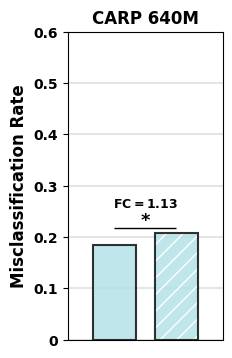

In [16]:
combined_correct_short = blb_correct_short + plp_correct_short
combined_incorrect_short = blb_incorrect_short + plp_incorrect_short
combined_correct_long = blb_correct_long + plp_correct_long
combined_incorrect_long = blb_incorrect_long + plp_incorrect_long


table_combined = [
    [combined_correct_long, combined_incorrect_long],
    [combined_correct_short, combined_incorrect_short]
]

p  = scipy.stats.chi2_contingency(table_combined)[1]

stars = p_val_to_stars(p)

misclass_rate_short = combined_incorrect_short / (combined_incorrect_short + combined_correct_short)
misclass_rate_long = combined_incorrect_long / (combined_incorrect_long + combined_correct_long)

print(misclass_rate_short, misclass_rate_long, p)

fig, ax = plt.subplots(figsize = (2,4))


ax.bar(
    [0,1], 
    [misclass_rate_short, misclass_rate_long], 
    width = 0.7, 
    color = "powderblue", 
    edgecolor = "black", 
    alpha = 0.8, 
    linewidth = 1.5, 
    zorder = 100
)
ax.set_ylim(bottom = 0)

hatch_list = ["", "//"]
patches = ax.patches
for patch, hatch in zip(patches, hatch_list):
    patch.set_hatch(hatch)
    patch._hatch_color = mcolors.to_rgba("white")

ax.tick_params(
    axis='x',          # changes apply to the x-axis
    which='both',      # both major and minor ticks are affected
    bottom=False,      # ticks along the bottom edge are off
    top=False,         # ticks along the top edge are off
    labelbottom=False
) 
# misclass_rate_short
ax.set_ylabel("Misclassification Rate", fontsize = 12, fontweight = "bold")
ax.set_ylim(bottom = 0, top = 0.6)
ax.set_yticks([0,0.1,0.2,0.3,0.4,0.5,0.6])
ax.set_yticklabels([0,0.1,0.2,0.3,0.4,0.5,0.6], fontweight = "bold")
for y_val in ax.get_yticks():
    ax.axhline(y = y_val, alpha = 0.1, color = "black", zorder = 1)

# ax.set_xticks([0,1])
# ax.set_xticklabels(["Short", "Long"])

ax.set_xlim(left = -0.75, right = 1.75)
hatch_list = ["", "//"]
patches = ax.patches
for patch, hatch in zip(patches, hatch_list):
    patch.set_hatch(hatch)
    patch._hatch_color = mcolors.to_rgba("white")
    
val = 0

y_bar_pos = np.max([misclass_rate_short, misclass_rate_long]) + 0.01

rect = mpatches.Rectangle((val , y_bar_pos), 1., 0.0005, clip_on = False, color = "black")
ax.add_patch(rect)

fc = misclass_rate_long / misclass_rate_short

ax.text(val + 0.5, y_bar_pos + 0.005, stars, fontweight = "bold", horizontalalignment = "center", fontsize = 13)
ax.text(val + 0.5, y_bar_pos+ 0.04, "$\mathbf{FC=" + str(round(fc, 2)) + "}$", fontweight = "bold", horizontalalignment = "center",  fontsize = 9)

ax.set_title(model_to_display_name[wanted_model], fontweight = "bold")


In [17]:
model_to_display_g = {
    "ESM-1 (43M) UR50" : "ESM-1\n(43M)\nUR50",
    "ESM-1 (670M) UR100": "ESM-1\n(670M)\nUR100",
    "ESM-1 (670M) UR50D": "ESM-1\n(670M)\nUR50D",
    "ESM-1 (670M) UR50S": "ESM-1\n(670M)\nUR50S",
    "ESM-1 (85M) UR50": "ESM-1\n(85M)\nUR50" ,
    "ESM-1b (650M) UR50": "ESM-1b\n(650M)\nUR50" ,
    "ESM-1v (650M) UR90": "ESM-1v\n(650M)\nUR90" ,
    "ESM-2 (150M) UR50": "ESM-2\n(150M)\nUR50" ,
    "ESM-2 (15B) UR50": "ESM-2\n(15B)\nUR50" ,
    "ESM-2 (35M) UR50": "ESM-2\n(35M)\nUR50" ,
    "ESM-2 (3B) UR50": "ESM-2\n(3B)\nUR50" ,
    "ESM-2 (650M) UR50": "ESM-2\n(650M)\nUR50" ,
    "ESM-2 (8M) UR50": "ESM-2\n(8M)\nUR50" ,
    "ProtBERT (420M) UR100": "Prot\nBERT\n(420M)\nUR100" ,
    "progen2_medium" : "PG2\n(764M)\n(UR90+\nBFD30)",
    "progen2_large" :  "PG2\n(2.7B)\n(UR90+\nBFD30)",
    "progen2_bfd" :   "PG2\n(2.7B)\n(BFD90)",
    "protbert_bfd" : "Prot\nBERT\n(420M)\nBFD100" ,
    "prott5_xl": "Prot\nT5\n(3B)\nUR50" ,
    "carp_38M": "CARP\n(38M)\nUR50" ,
    "carp_76M": "CARP\n(76M)\nUR50" ,
    "carp_640M": "CARP\n(640M)\nUR50" ,
    
}

"ESM-1 (43M) UR50" 0.1825239507912521
"ESM-1 (670M) UR100" 0.1455561550909337
"ESM-1 (670M) UR50D" 0.16386898300282912
"ESM-1 (670M) UR50S" 0.16580180978118086
"ESM-1 (85M) UR50" 0.17130686316932972
"ESM-1b (650M) UR50" 0.1580542371285938
"ESM-1v (650M) UR90" 0.2272997388398291
"ESM-2 (150M) UR50" 0.13903634647546298
"ESM-2 (15B) UR50" 0.12651451203663264
"ESM-2 (35M) UR50" 0.14906510000483014
"ESM-2 (3B) UR50" 0.13489922435079663
"ESM-2 (650M) UR50" 0.14027291663321945
"ESM-2 (8M) UR50" 0.16391287207126273
"ProtBERT (420M) UR100" 0.30278217764449605
progen2_medium 0.14873168355701422
progen2_medium
progen2_large 0.17493108484200445
progen2_large
progen2_bfd 0.14872575627161286
progen2_bfd
prott5_xl 0.09199712865740269
prott5_xl
carp_38M 0.11742264797089913
carp_38M
carp_76M 0.12714668328121717
carp_76M
carp_640M 0.13683522109312607
carp_640M


Text(0.5, 1.01, 'Per-gene rates of prediction mismatch between tiles')

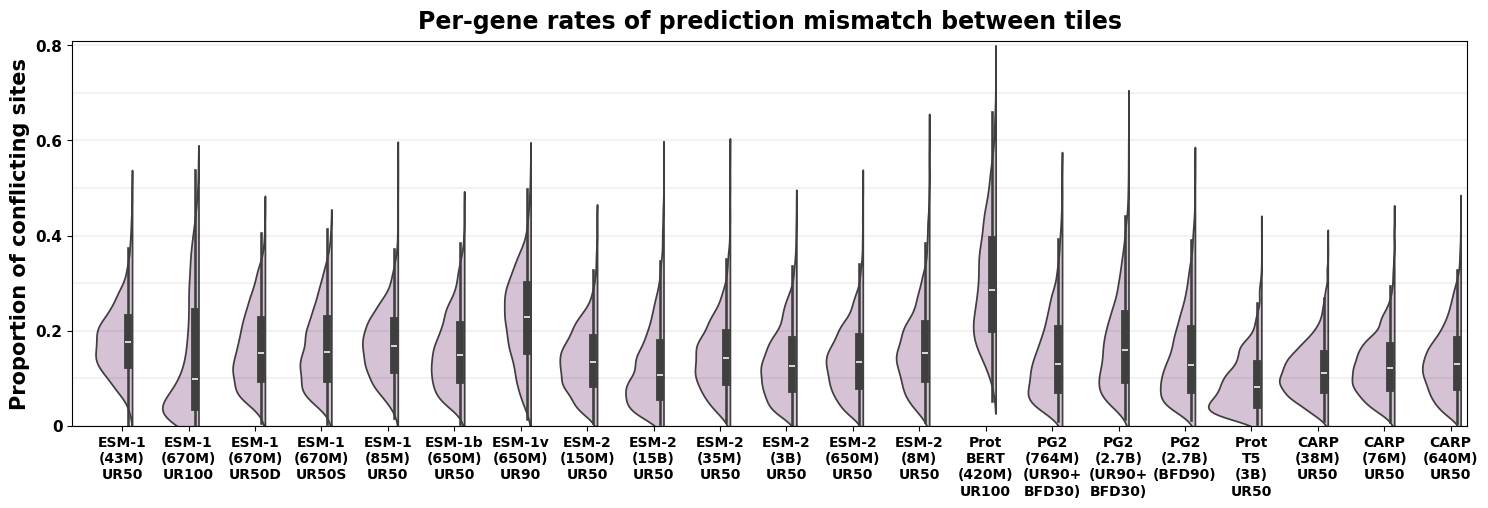

In [18]:
summary_stats_path = f"{home_path}singh/nlp_review/revisions/scripts/human_proteome_long_tiled/additional_summary_files_results/"
summary_sats_files = glob.glob(summary_stats_path + "*.csv")

data = []
labels = []

old_mismatch_data = pd.read_csv(supp_table_path + "gene_ref_aas_different.csv")

for m, sub_df in old_mismatch_data.groupby("model"):
    print("\"" + m + "\"", np.mean(sub_df["proportion_different"].values))
    labels.append(model_to_display_g[m])
    data.append(sub_df["proportion_different"].values)
    
model_order = ["progen2_medium", "progen2_large", "progen2_bfd", "prott5_xl", "carp_38M", "carp_76M", "carp_640M"]


new_df_list = []

for m in model_order:
    df = pd.read_csv(summary_stats_path + "summary_stats_" + m + ".csv", index_col = 0)
    df["model"] = m 
    labels.append(model_to_display_g[m])
    data.append(df["proportion_different"].values)
    print(m, np.mean(df["proportion_different"].values))
    print(m)
    
    new_df_list.append(df)
    
fig, ax = plt.subplots(figsize = (18,5))


sns.violinplot(data, split = True, color = "thistle", cut = True,)
ax.set_ylim(top = 0.81, bottom = 0)
for y_val in ax.get_yticks():
    ax.axhline(y=y_val, zorder = 1, color = "black", alpha = 0.05)
    
x_ticks = np.arange(0.25, len(data) + 0.25, 1)
ax.set_xticks(x_ticks)
ax.set_xticklabels(labels, fontweight = "bold", fontsize = 10)
ax.set_yticks([0,0.2,0.4,0.6,0.8])
ax.set_yticklabels([0,0.2,0.4,0.6,0.8], fontsize = 11, fontweight = "bold")

ax.set_ylabel("Proportion of conflicting sites", fontsize =15, fontweight = "bold")

ax.set_title("Per-gene rates of prediction mismatch between tiles", fontweight = "bold", fontsize =17, y = 1.01 )




In [19]:
new_df_mismatch = pd.concat(new_df_list)
new_df_mismatch = new_df_mismatch[["model", "gene", "proportion_different"]]
joined_mismatch_data = pd.concat([new_df_mismatch, old_mismatch_data])


m_set = set(joined_mismatch_data["model"].values)

name_dict = {}
for m in m_set:
    name_dict[m] = m 

model_name_converter = {
    "ProtBERT" : "ProtBERT UR100",
    "progen2_medium" : "ProGen2 (764M) UR90 BFD30",
    "progen2_large" : "ProGen2 (2.7B) UR90 BFD30",
    "progen2_bfd" : "ProGen2 (2.7B) BFD90",
    "protbert_bfd" : "ProtBERT BFD100",
    "prott5_xl" : "ProtT5-XL",
    "carp_38M" : "CARP (38M)",
    "carp_640M" : "CARP (640M)",
    "carp_76M" : "CARP (76M)"
}

for k, v in model_name_converter.items():
    name_dict[k] = v
    
joined_mismatch_data["model"] = joined_mismatch_data["model"].apply(lambda x : name_dict[x])
joined_mismatch_data.to_csv(supp_table_path + "revisions/r_gene_ref_aas_different.csv")

In [20]:
model_to_boxplot_data = {}
model_to_boxplot_data_name_tracker = {} # used for putting together supplemental table 

model_to_density_plot_data = {}
model_to_plp_error_info = {}
model_to_blb_error_info = {}
model_to_combined_error_info = {}

wanted_model = "carp_640M"

model_list = [
    "progen2_medium", 
    "progen2_large", 
    "progen2_bfd", 
#     "protbert_bfd", 
    "prott5_xl", 
    "carp_38M", 
    "carp_76M", 
    "carp_640M"
]

for wanted_model in model_list:
    
    model_data = model_to_data[wanted_model]

    found = 0 
    not_found = 0

    short_variants_scores = {}

    for index, row in short_variants.iterrows():
        score = model_data[row["gene_name"]]["scores"][row["name"]]
        short_variants_scores[row["full_name"]] = score

    long_score_path = f"../../../revisions/data/new_models/human_proteome_long_tiled_combined_csvs/{wanted_model}/"

    t1 = time.time()

    long_variants_tiled_scores = {}

    for g, sub_df in long_variants.groupby("gene_name"):
        df = pd.read_csv(long_score_path + g + ".csv.gz")
        variant_to_score = dict(zip(df["name"].values, df["weighted_score"].values))
        for index, row in sub_df.iterrows():
            v_name = g + "_" + row["name"]
            long_variants_tiled_scores[v_name] = variant_to_score[row["name"]]



    short_variants_plp_scores = []
    short_variants_blb_scores = []
    short_variants_vus_scores = []
    
    short_variants_plp_names = []
    short_variants_blb_names = []
    short_variants_vus_names = []

    long_variants_plp_scores = []
    long_variants_blb_scores = []
    long_variants_vus_scores = []
    
    long_variants_plp_names = []
    long_variants_blb_names = []
    long_variants_vus_names = []


    all_vus = set(needed_variants_df.loc[needed_variants_df["clinvar_annotation"] == "VUS"]["full_name"].values)
    all_plp = set(needed_variants_df.loc[needed_variants_df["clinvar_annotation"] == "PLP"]["full_name"].values)
    all_blb = set(needed_variants_df.loc[needed_variants_df["clinvar_annotation"] == "BLB"]["full_name"].values)


    for k, v in  long_variants_tiled_scores.items():
        if k in all_vus:
            long_variants_vus_scores.append(v)
            long_variants_vus_names.append(k)
        elif k in all_plp:
            long_variants_plp_scores.append(v)
            long_variants_plp_names.append(k)
        elif k in all_blb:
            long_variants_blb_scores.append(v)
            long_variants_blb_names.append(k)

    for k, v in  short_variants_scores.items():
        if k in all_vus:
            short_variants_vus_scores.append(v)
            short_variants_vus_names.append(k)
        elif k in all_plp:
            short_variants_plp_scores.append(v)
            short_variants_plp_names.append(k)
        elif k in all_blb:
            short_variants_blb_scores.append(v)
            short_variants_blb_names.append(k)

    boxplot_data_name_tracker = [long_variants_blb_names, short_variants_blb_names , long_variants_vus_names, short_variants_vus_names, long_variants_plp_names, short_variants_plp_names]
    boxplot_data = [long_variants_blb_scores, short_variants_blb_scores , long_variants_vus_scores, short_variants_vus_scores, long_variants_plp_scores, short_variants_plp_scores]
    
    model_to_boxplot_data[wanted_model] = boxplot_data
    model_to_boxplot_data_name_tracker[wanted_model] = boxplot_data_name_tracker 

    all_train = set(needed_variants_df.loc[needed_variants_df["train_test_split"] == "Train"]["full_name"].values)
    all_test = set(needed_variants_df.loc[needed_variants_df["train_test_split"] == "Test"]["full_name"].values)


    all_vus = set(needed_variants_df.loc[needed_variants_df["clinvar_annotation"] == "VUS"]["full_name"].values)
    all_plp = set(needed_variants_df.loc[needed_variants_df["clinvar_annotation"] == "PLP"]["full_name"].values)
    all_blb = set(needed_variants_df.loc[needed_variants_df["clinvar_annotation"] == "BLB"]["full_name"].values)


    train_plp_long = []
    train_plp_short = []
    train_blb_long = []
    train_blb_short = []

    test_plp_long = []
    test_plp_short = []
    test_blb_short = []
    test_blb_long = []



    for k, v in  short_variants_scores.items():
        if k in all_plp:
            if k in all_train:
                train_plp_short.append(v)

            elif k in all_test:
                test_plp_short.append(v)

        elif k in all_blb:
            if k in all_train:
                train_blb_short.append(v)
            elif k in all_test:
                test_blb_short.append(v)


    for k, v in  long_variants_tiled_scores.items():
        if k in all_plp:
            if k in all_train:
                train_plp_long.append(v)

            elif k in all_test:
                test_plp_long.append(v)

        elif k in all_blb:
            if k in all_train:
                train_blb_long.append(v)
            elif k in all_test:
                test_blb_long.append(v)


    all_train_plp = train_plp_long + train_plp_short
    all_train_blb = train_blb_long + train_blb_short

    max_accuracy, argmax_acc, argmax_conf = get_argmax_accuracy_point(all_train_plp, all_train_blb)

    density_plot_data = {
        "max_acc" : max_accuracy,
        "argmax_acc" : argmax_acc,
        "argmax_conf" : argmax_conf,
        "all_train_plp" : all_train_plp,
        "all_train_blb" : all_train_blb
    }

    model_to_density_plot_data[wanted_model] = density_plot_data


    plp_correct_short = len(list(filter(lambda x : x <= argmax_acc, test_plp_short)))
    plp_incorrect_short = len(list(filter(lambda x : x >  argmax_acc, test_plp_short)))


    plp_correct_long = len(list(filter(lambda x : x <= argmax_acc, test_plp_long)))
    plp_incorrect_long = len(list(filter(lambda x : x > argmax_acc, test_plp_long)))


    misclass_rate_short = plp_incorrect_short / (plp_incorrect_short + plp_correct_short)
    misclass_rate_long = plp_incorrect_long / (plp_incorrect_long + plp_correct_long)
    fc = misclass_rate_long / misclass_rate_short

    table_plp = [
        [plp_correct_long, plp_incorrect_long],
        [plp_correct_short, plp_incorrect_short]
    ]

    p  = scipy.stats.chi2_contingency(table_plp)[1]

    stars = p_val_to_stars(p)

    error_rate_data_plp = {
        "plp_correct_short" : plp_correct_short,
        "plp_incorrect_short" : plp_incorrect_short,
        "plp_correct_long" : plp_correct_long,
        "plp_incorrect_long" : plp_incorrect_long,
        "table_plp" : table_plp,
        "chi_p" : p,
        "stars" : stars,
        "misclass_rate_short" : misclass_rate_short,
        "misclass_rate_long" : misclass_rate_long,
        "fc" : fc
    }

    model_to_plp_error_info[wanted_model] = error_rate_data_plp

    blb_correct_short = len(list(filter(lambda x : x > argmax_acc, test_blb_short)))
    blb_incorrect_short = len(list(filter(lambda x : x <=  argmax_acc, test_blb_short)))


    blb_correct_long = len(list(filter(lambda x : x > argmax_acc, test_blb_long)))
    blb_incorrect_long = len(list(filter(lambda x : x <= argmax_acc, test_blb_long)))

    table_blb = [
        [blb_correct_long, blb_incorrect_long],
        [blb_correct_short, blb_incorrect_short]
    ]

    p  = scipy.stats.chi2_contingency(table_blb)[1]

    stars = p_val_to_stars(p)
    misclass_rate_short = blb_incorrect_short / (blb_incorrect_short + blb_correct_short)
    misclass_rate_long = blb_incorrect_long / (blb_incorrect_long + blb_correct_long)

    fc = misclass_rate_long / misclass_rate_short


    error_rate_data_blb = {
        "blb_correct_short" : blb_correct_short,
        "blb_incorrect_short" : blb_incorrect_short,
        "blb_correct_long" : blb_correct_long,
        "blb_incorrect_long" : blb_incorrect_long,
        "table_blb" : table_blb,
        "chi_p" : p,
        "stars" : stars,
        "misclass_rate_short" : misclass_rate_short,
        "misclass_rate_long" : misclass_rate_long,
        "fc" : fc
    }

    model_to_blb_error_info[wanted_model] = error_rate_data_blb

    combined_correct_short = blb_correct_short + plp_correct_short
    combined_incorrect_short = blb_incorrect_short + plp_incorrect_short
    combined_correct_long = blb_correct_long + plp_correct_long
    combined_incorrect_long = blb_incorrect_long + plp_incorrect_long


    table_combined = [
        [combined_correct_long, combined_incorrect_long],
        [combined_correct_short, combined_incorrect_short]
    ]

    p  = scipy.stats.chi2_contingency(table_combined)[1]

    stars = p_val_to_stars(p)

    misclass_rate_short = combined_incorrect_short / (combined_incorrect_short + combined_correct_short)
    misclass_rate_long = combined_incorrect_long / (combined_incorrect_long + combined_correct_long)

    fc = misclass_rate_long / misclass_rate_short


    error_rate_data_combined = {
        "combined_correct_short" : combined_correct_short,
        "combined_incorrect_short" : combined_incorrect_short,
        "combined_correct_long" : combined_correct_long,
        "combined_incorrect_long" : combined_incorrect_long,
        "table_combined" : table_combined,
        "chi_p" : p,
        "stars" : stars,
        "misclass_rate_short" : misclass_rate_short,
        "misclass_rate_long" : misclass_rate_long,
        "fc" : fc
    }

    model_to_combined_error_info[wanted_model] = error_rate_data_combined

    t2 = time.time()

    print(wanted_model, t2 - t1)

/tmp/ipykernel_1962772/3128240770.py:42: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + g + ".csv.gz")
/tmp/ipykernel_1962772/3128240770.py:42: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + g + ".csv.gz")
/tmp/ipykernel_1962772/3128240770.py:42: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + g + ".csv.gz")
/tmp/ipykernel_1962772/3128240770.py:42: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + g + ".csv.gz")
/tmp/ipykernel_1962772/3128240770.py:42: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + 

progen2_medium 81.86059165000916


/tmp/ipykernel_1962772/3128240770.py:42: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + g + ".csv.gz")
/tmp/ipykernel_1962772/3128240770.py:42: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + g + ".csv.gz")
/tmp/ipykernel_1962772/3128240770.py:42: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + g + ".csv.gz")
/tmp/ipykernel_1962772/3128240770.py:42: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + g + ".csv.gz")
/tmp/ipykernel_1962772/3128240770.py:42: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + 

progen2_large 81.75172233581543


/tmp/ipykernel_1962772/3128240770.py:42: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + g + ".csv.gz")
/tmp/ipykernel_1962772/3128240770.py:42: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + g + ".csv.gz")
/tmp/ipykernel_1962772/3128240770.py:42: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + g + ".csv.gz")
/tmp/ipykernel_1962772/3128240770.py:42: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + g + ".csv.gz")
/tmp/ipykernel_1962772/3128240770.py:42: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + 

...

carp_38M 82.94361996650696


/tmp/ipykernel_1962772/3128240770.py:42: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + g + ".csv.gz")
/tmp/ipykernel_1962772/3128240770.py:42: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + g + ".csv.gz")
/tmp/ipykernel_1962772/3128240770.py:42: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + g + ".csv.gz")
/tmp/ipykernel_1962772/3128240770.py:42: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + g + ".csv.gz")
/tmp/ipykernel_1962772/3128240770.py:42: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + 

carp_76M 83.26021599769592


/tmp/ipykernel_1962772/3128240770.py:42: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + g + ".csv.gz")
/tmp/ipykernel_1962772/3128240770.py:42: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + g + ".csv.gz")
/tmp/ipykernel_1962772/3128240770.py:42: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + g + ".csv.gz")
/tmp/ipykernel_1962772/3128240770.py:42: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + g + ".csv.gz")
/tmp/ipykernel_1962772/3128240770.py:42: DtypeWarning: Columns (7,8,9,10,11) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(long_score_path + 

carp_640M 59.93605446815491


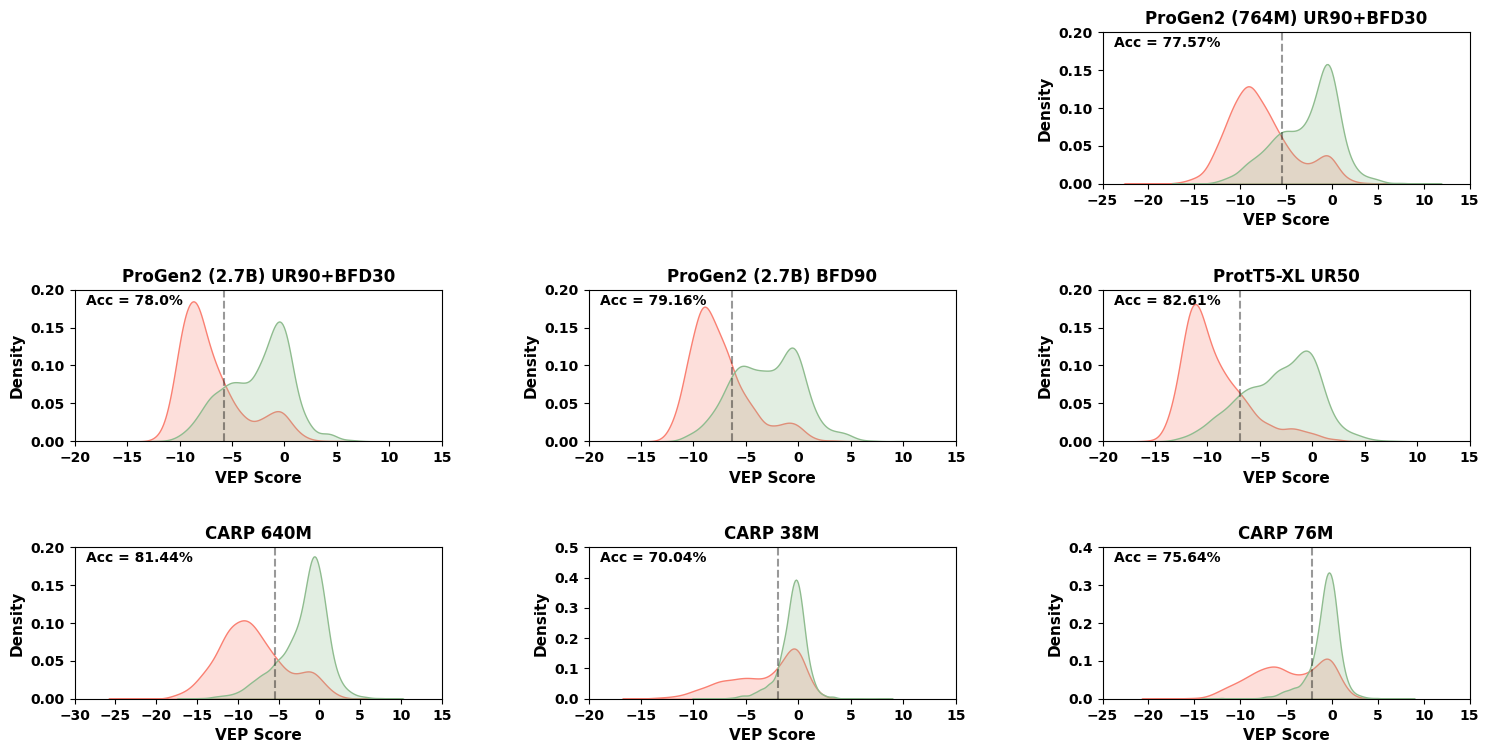

In [21]:

model_to_display_h = {
    "progen2_medium" : "ProGen2 (764M) UR90+BFD30",
    "progen2_large" : "ProGen2 (2.7B) UR90+BFD30",
    "progen2_bfd" : "ProGen2 (2.7B) BFD90"
}

fig, axes = plt.subplots(4, 3, figsize = (18, 12))
fig.subplots_adjust(hspace = 0.7, wspace = 0.4)
axes = axes.ravel()

model_list = [
    "progen2_medium", 
    "progen2_large", 
    "progen2_bfd", 
    "prott5_xl", 
    "carp_640M",
    "carp_38M", 
    "carp_76M", 
]


for i, m in enumerate(model_list):
    ax = axes[i + 2]
    density_data = model_to_density_plot_data[m]
    
    all_train_plp = density_data["all_train_plp"]
    all_train_blb = density_data["all_train_blb"]
    argmax_acc = density_data["argmax_acc"]
    max_accuracy = density_data["max_acc"]
    
    sns.kdeplot(all_train_plp, ax = ax, fill = True, color = "salmon", label = "P/LP")
    sns.kdeplot(all_train_blb, ax = ax, fill = True, color = "darkseagreen", label = "B/LB")



    ax.set_xlabel("VEP Score", fontsize = 11, fontweight = "bold")
    if m in model_to_display_h.keys():
        
        ax.set_title(model_to_display_h[m], fontsize = 12, fontweight = "bold")
    else:
        ax.set_title(model_to_display_name[m], fontsize = 12, fontweight = "bold")
    ax.set_ylabel("Density", fontsize = 11, fontweight = "bold")
    ax.set_yticks(ax.get_yticks())
    ax.set_xticks(ax.get_xticks())
    ax.set_xticklabels(ax.get_xticklabels(), fontweight = "bold")
    ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")

    ax.axvline(x = argmax_acc, linestyle = "--", color = "black", alpha = 0.4,label = "$\phi_m$")
#     ax.legend(loc = "upper right")

    acc_str = str(round(max_accuracy * 100, 2)) + "%"

    ax.text(0.03, 0.9, "Acc = " + acc_str, transform = ax.transAxes, fontweight = "bold")
    
fig.delaxes(axes[0])
fig.delaxes(axes[1])
fig.delaxes(axes[-3])
fig.delaxes(axes[-2])
fig.delaxes(axes[-1])

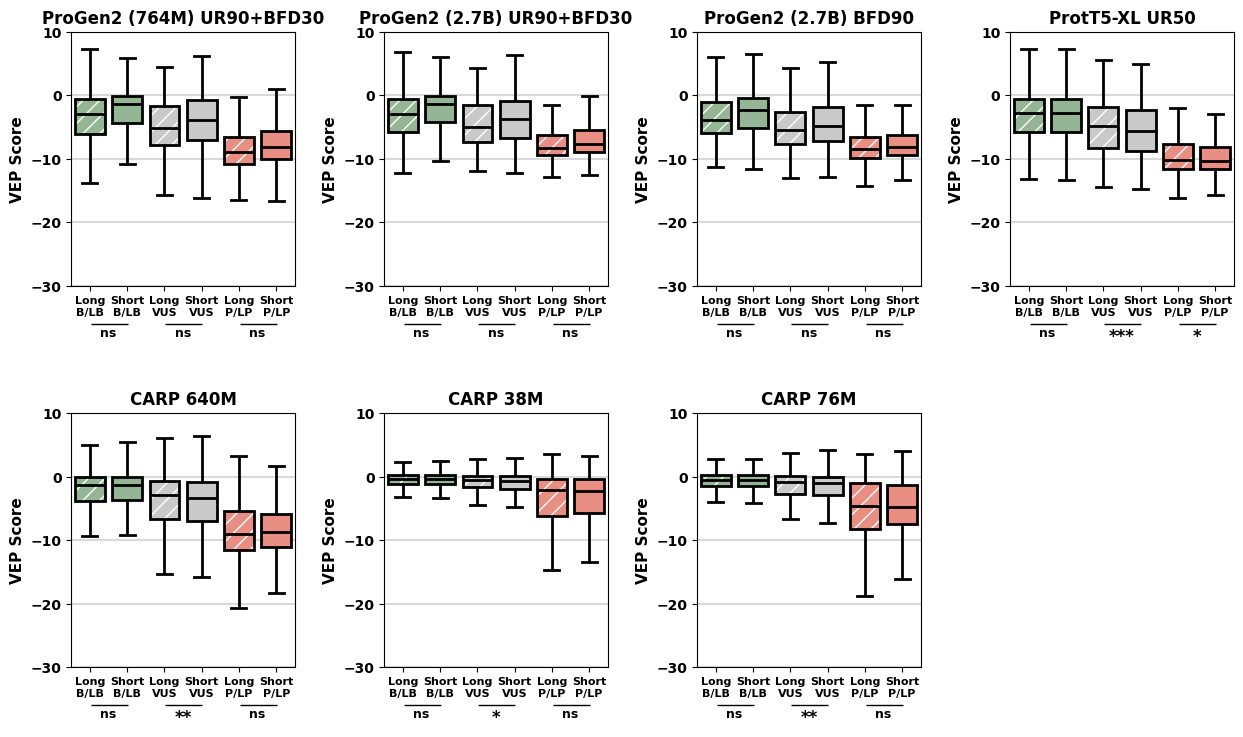

In [22]:
fig, axes = plt.subplots(2, 4, figsize = (15, 8.25))
fig.subplots_adjust(hspace = 0.5, wspace = 0.4)
axes = axes.ravel()

for i, m in enumerate(model_list):
    ax = axes[i]
    boxplot_data = model_to_boxplot_data[m]
    
    
    my_pal = {
        0 : "darkseagreen", 
        1 : "darkseagreen", 
        2 : "#c9c9c9", 
        3 : "#c9c9c9", 
        4 : "salmon", 
        5 : "salmon"
    }


    ax = sns.boxplot(
        boxplot_data,
        palette = my_pal,
        showfliers = False,
        boxprops=dict(linewidth=2, edgecolor='black', zorder = 100),
        medianprops=dict(linewidth=2, color='black', zorder = 100),
        whiskerprops=dict(linewidth=2, color='black', zorder = 100),
        capprops = dict(linewidth=2, color='black', zorder = 100),
        ax = ax
    )

    patches = [patch for patch in ax.patches if type(patch) == mpatches.PathPatch]

    hatch_list = ["//", "", "//", "", "//", ""]
    for patch, hatch in zip(patches, hatch_list):
        patch.set_hatch(hatch)

    hatch_colors = ["white", "gray", "white", "gray", "white", "gray"]
    for i, patch in enumerate(ax.patches):
        patch._hatch_color = mcolors.to_rgba(hatch_colors[i])


    ax.set_yticks([-30, -20, -10, 0, 10])
    ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")

    for y_val in ax.get_yticks():
        ax.axhline(y = y_val, color = "black", alpha = 0.15, zorder = 1)

    ax.set_xticks(ax.get_xticks())
    ax.set_xticklabels(
        [
            "Long\nB/LB",
            "Short\nB/LB",
    #         "",
            "Long\nVUS",
            "Short\nVUS",
    #         "",
            "Long\nP/LP",
            "Short\nP/LP",
        ],
        fontsize = 8,
        fontweight = "bold"
    )

    rect1 = mpatches.Rectangle(((1/6)-0.08, -0.15), 1/6, 0.002,  transform = ax.transAxes, clip_on = False, color = "black")
    rect2 = mpatches.Rectangle((3/6-0.08, -0.15), 1/6, 0.002, transform = ax.transAxes,clip_on = False, color = "black")
    rect3 = mpatches.Rectangle((5/6-0.08, -0.15), 1/6, 0.002,transform = ax.transAxes, clip_on = False, color = "black")
    ax.add_patch(rect1)
    ax.add_patch(rect2)
    ax.add_patch(rect3)
    
    st, p = scipy.stats.mannwhitneyu(boxplot_data[0], boxplot_data[1] , alternative = "greater")
    p_str = format_p(p)
    p_stars = p_val_to_stars(p)
    ax.text(1/6,  -0.2 if p_stars == "ns" else -0.22, p_stars , transform = ax.transAxes, horizontalalignment = "center", fontsize = 9 if p_stars == "ns" else 12, fontweight = "bold")

    st, p = scipy.stats.mannwhitneyu(boxplot_data[2], boxplot_data[3] , alternative = "greater")
    p_str = format_p(p)

    p_stars = p_val_to_stars(p)
    ax.text(3/6,  -0.2 if p_stars == "ns" else -0.22, p_stars, transform = ax.transAxes, horizontalalignment = "center", fontsize = 9 if p_stars == "ns" else 12, fontweight = "bold")


    st, p = scipy.stats.mannwhitneyu(boxplot_data[4], boxplot_data[5], alternative = "greater")
    p_stars = p_val_to_stars(p)
    ax.text(5/6,  -0.2 if p_stars == "ns" else -0.22, p_stars, transform = ax.transAxes, horizontalalignment = "center", fontsize = 9 if p_stars == "ns" else 12, fontweight = "bold")

    ax.set_ylabel("VEP Score", fontsize = 11, fontweight = "bold")
#     ax.set_title(model_to_display_name[m], fontsize = 13, fontweight = "bold")
    
    if m in model_to_display_h.keys():
        
        ax.set_title(model_to_display_h[m], fontsize = 12, fontweight = "bold")
    else:
        ax.set_title(model_to_display_name[m], fontsize = 12, fontweight = "bold")

        
fig.delaxes(axes[-1])


/tmp/ipykernel_1962772/680489946.py:84: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  patch0 = mpatches.Patch(color = "salmon", edgecolor = "black", linewidth = 1, alpha = 0.8, label='Short Protein P/LP')
/tmp/ipykernel_1962772/680489946.py:87: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  patch1 = mpatches.Patch(color = "salmon", edgecolor = "black", linewidth = 1, alpha = 0.8, label='Long Protein P/LP')


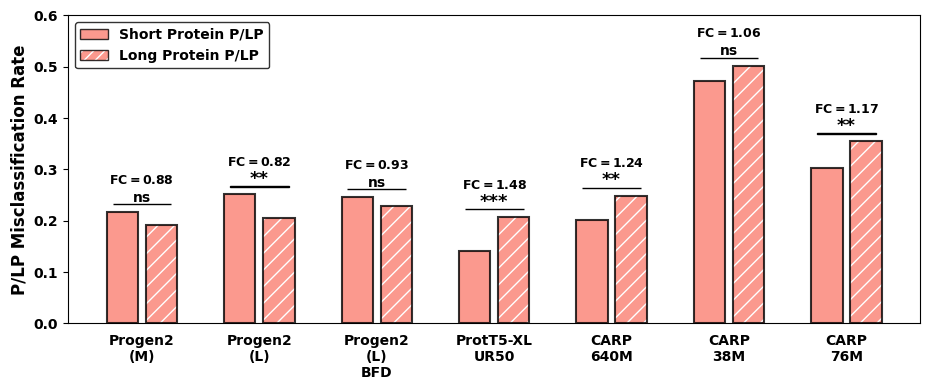

In [23]:
x = []
y = []

p_list = []
name_list = []
y_bar_pos_list = []
fc_list = []
star_list = []
labels_list = []

i = 0

for m in model_list:
    info = model_to_plp_error_info[m]
    
    misclass_rate_short = info["misclass_rate_short"]
    misclass_rate_long = info["misclass_rate_long"]
    fc = info["fc"]
    
    chi_p = info["chi_p"]
    p_list.append(format_p(chi_p))
    fc_list.append(fc)
    y_bar_pos_list.append(max(misclass_rate_long, misclass_rate_short) + 0.015)
    star_list.append(info["stars"])
    
    x.append(i)
    y.append(misclass_rate_short)
   
    i+=1
    x.append(i)
    y.append(misclass_rate_long)
    i+=1
    i+=1
    
    labels_list.append(model_to_display_name[m].replace(" ", "\n"))
    
    
    
    
fig, ax = plt.subplots(figsize = (11,4))
ax.bar(x,y, color = "salmon", edgecolor = "black", alpha = 0.8, linewidth = 1.5, zorder = 100)
ax.set_ylim(bottom = 0)
    

hatch_list = ["", "//"] * len(model_list)
patches = ax.patches
for patch, hatch in zip(patches, hatch_list):
    patch.set_hatch(hatch)
    patch._hatch_color = mcolors.to_rgba("white")

ax.tick_params(
    axis='x',          # changes apply to the x-axis
    which='both',      # both major and minor ticks are affected
    bottom=False,      # ticks along the bottom edge are off
    top=False,         # ticks along the top edge are off
    labelbottom=False
) 



for i , val in enumerate(np.arange(0.5,(3*len(model_list)),3)):
#     ax.text(val , -0.04, model_to_base_string[model_list[i]], horizontalalignment = "center", fontweight = "bold")
#     ax.text(val , -0.1, model_to_dataset_string[model_list[i]], horizontalalignment = "center", fontweight = "bold", color = dataset_to_color[model_to_dataset_string[needed_models[i]]])
#     ax.text(val , -0.07, model_to_params_string[model_list[i]], horizontalalignment = "center", fontweight = "bold")
    
    ax.text( val , -0.02, labels_list[i],horizontalalignment = "center", fontweight = "bold", verticalalignment = "top")
    rect = mpatches.Rectangle((val-0.75, y_bar_pos_list[i]), 1.5, 0.0005, clip_on = False, color = "black")
    ax.add_patch(rect)
    
    fs = 13
    if star_list[i] == "ns":
        fs = 10
    ax.text(val, y_bar_pos_list[i] + 0.005, star_list[i], fontweight = "bold", horizontalalignment = "center", fontsize = fs)
    ax.text(val, y_bar_pos_list[i] + 0.04, "$\mathbf{FC=" + str(round(fc_list[i], 2)) + "}$", fontweight = "bold", horizontalalignment = "center",  fontsize = 9)
    
ax.set_yticks(ax.get_yticks())
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")


# for y_val in ax.get_yticks():
#     ax.axhline(y = y_val, color = "black", alpha = 0.2, zorder = 1)

ax.set_ylabel("P/LP Misclassification Rate", fontsize = 12, fontweight = "bold")
patch0 = mpatches.Patch(color = "salmon", edgecolor = "black", linewidth = 1, alpha = 0.8, label='Short Protein P/LP')
patch0.set_edgecolor("black")

patch1 = mpatches.Patch(color = "salmon", edgecolor = "black", linewidth = 1, alpha = 0.8, label='Long Protein P/LP')
patch1.set_hatch("///")
patch1.set_edgecolor("black")
patch1._hatch_color = mcolors.to_rgba("white")
plt.legend(handles=[patch0, patch1], loc = "upper left", prop = {"weight" : "bold"}, edgecolor = "black")



/tmp/ipykernel_1962772/2534088864.py:84: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  patch0 = mpatches.Patch(color = "darkseagreen", edgecolor = "black", linewidth = 1, alpha = 0.7, label='Short Protein B/LB')
/tmp/ipykernel_1962772/2534088864.py:87: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  patch1 = mpatches.Patch(color = "darkseagreen", edgecolor = "black", linewidth = 1, alpha = 0.7, label='Long Protein B/LB')


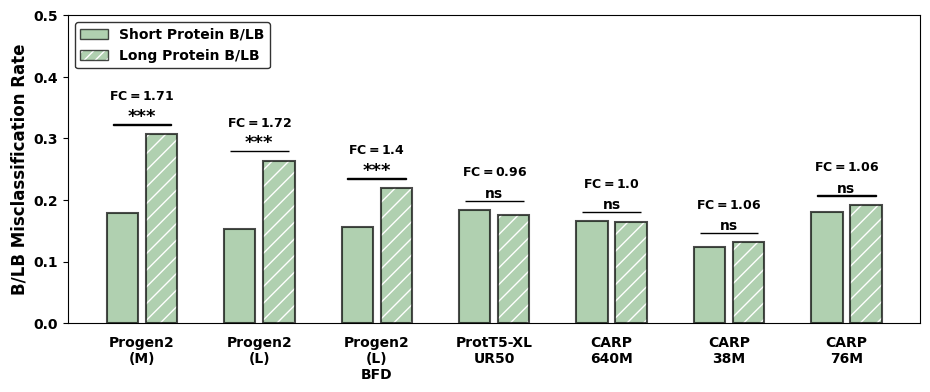

In [24]:
x = []
y = []

p_list = []
name_list = []
y_bar_pos_list = []
fc_list = []
star_list = []
labels_list = []

i = 0

for m in model_list:
    info = model_to_blb_error_info[m]
    
    misclass_rate_short = info["misclass_rate_short"]
    misclass_rate_long = info["misclass_rate_long"]
    fc = info["fc"]
    
    chi_p = info["chi_p"]
    p_list.append(format_p(chi_p))
    fc_list.append(fc)
    y_bar_pos_list.append(max(misclass_rate_long, misclass_rate_short) + 0.015)
    star_list.append(info["stars"])
    
    x.append(i)
    y.append(misclass_rate_short)
   
    i+=1
    x.append(i)
    y.append(misclass_rate_long)
    i+=1
    i+=1
    
    labels_list.append(model_to_display_name[m].replace(" ", "\n"))
    
    
    
    
fig, ax = plt.subplots(figsize = (11,4))
ax.bar(x,y, color = "darkseagreen", edgecolor = "black", alpha = 0.7, linewidth = 1.5)
ax.set_ylim(bottom = 0)
    

hatch_list = ["", "//"] * len(model_list)
patches = ax.patches
for patch, hatch in zip(patches, hatch_list):
    patch.set_hatch(hatch)
    patch._hatch_color = mcolors.to_rgba("white")

ax.tick_params(
    axis='x',          # changes apply to the x-axis
    which='both',      # both major and minor ticks are affected
    bottom=False,      # ticks along the bottom edge are off
    top=False,         # ticks along the top edge are off
    labelbottom=False
) 



for i , val in enumerate(np.arange(0.5,(3*len(model_list)),3)):
#     ax.text(val , -0.04, model_to_base_string[model_list[i]], horizontalalignment = "center", fontweight = "bold")
#     ax.text(val , -0.1, model_to_dataset_string[model_list[i]], horizontalalignment = "center", fontweight = "bold", color = dataset_to_color[model_to_dataset_string[needed_models[i]]])
#     ax.text(val , -0.07, model_to_params_string[model_list[i]], horizontalalignment = "center", fontweight = "bold")
    
    ax.text( val , -0.02, labels_list[i],horizontalalignment = "center", fontweight = "bold", verticalalignment = "top")
    rect = mpatches.Rectangle((val-0.75, y_bar_pos_list[i]), 1.5, 0.0005, clip_on = False, color = "black")
    ax.add_patch(rect)
    
    fs = 13
    if star_list[i] == "ns":
        fs = 10
    ax.text(val, y_bar_pos_list[i] + 0.005, star_list[i], fontweight = "bold", horizontalalignment = "center", fontsize = fs)
    ax.text(val, y_bar_pos_list[i] + 0.04, "$\mathbf{FC=" + str(round(fc_list[i], 2)) + "}$", fontweight = "bold", horizontalalignment = "center",  fontsize = 9)
    
ax.set_yticks([0,0.1,0.2,0.3,0.4,0.5])
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")


# for y_val in ax.get_yticks():
#     ax.axhline(y = y_val, color = "black", alpha = 0.2, zorder = 1)

ax.set_ylabel("B/LB Misclassification Rate", fontsize = 12, fontweight = "bold")
patch0 = mpatches.Patch(color = "darkseagreen", edgecolor = "black", linewidth = 1, alpha = 0.7, label='Short Protein B/LB')
patch0.set_edgecolor("black")

patch1 = mpatches.Patch(color = "darkseagreen", edgecolor = "black", linewidth = 1, alpha = 0.7, label='Long Protein B/LB')
patch1.set_hatch("///")
patch1.set_edgecolor("black")
patch1._hatch_color = mcolors.to_rgba("white")
plt.legend(handles=[patch0, patch1], loc = "upper left", prop = {"weight" : "bold"}, edgecolor = "black")


/tmp/ipykernel_1962772/2995335894.py:84: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  patch0 = mpatches.Patch(color = "powderblue", edgecolor = "black", linewidth = 1, alpha = 0.7, label='Short Protein')
/tmp/ipykernel_1962772/2995335894.py:87: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  patch1 = mpatches.Patch(color = "powderblue", edgecolor = "black", linewidth = 1, alpha = 0.7, label='Long Protein')


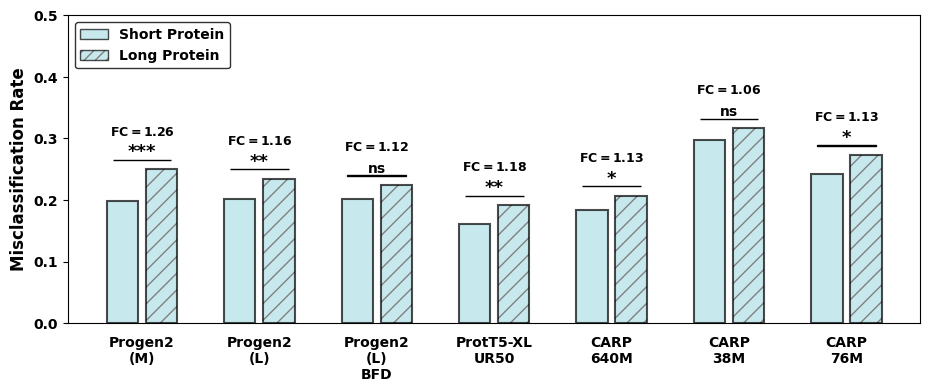

In [25]:
x = []
y = []

p_list = []
name_list = []
y_bar_pos_list = []
fc_list = []
star_list = []
labels_list = []

i = 0

for m in model_list:
    info = model_to_combined_error_info[m]
    
    misclass_rate_short = info["misclass_rate_short"]
    misclass_rate_long = info["misclass_rate_long"]
    fc = info["fc"]
    
    chi_p = info["chi_p"]
    p_list.append(format_p(chi_p))
    fc_list.append(fc)
    y_bar_pos_list.append(max(misclass_rate_long, misclass_rate_short) + 0.015)
    star_list.append(info["stars"])
    
    x.append(i)
    y.append(misclass_rate_short)
   
    i+=1
    x.append(i)
    y.append(misclass_rate_long)
    i+=1
    i+=1
    
    labels_list.append(model_to_display_name[m].replace(" ", "\n"))
    
    
    
    
fig, ax = plt.subplots(figsize = (11,4))
ax.bar(x,y, color = "powderblue", edgecolor = "black", alpha = 0.7, linewidth = 1.5)
ax.set_ylim(bottom = 0)
    

hatch_list = ["", "//"] * len(model_list)
patches = ax.patches
for patch, hatch in zip(patches, hatch_list):
    patch.set_hatch(hatch)
    patch._hatch_color = mcolors.to_rgba("gray")

ax.tick_params(
    axis='x',          # changes apply to the x-axis
    which='both',      # both major and minor ticks are affected
    bottom=False,      # ticks along the bottom edge are off
    top=False,         # ticks along the top edge are off
    labelbottom=False
) 



for i , val in enumerate(np.arange(0.5,(3*len(model_list)),3)):
    
    ax.text( val , -0.02, labels_list[i],horizontalalignment = "center", fontweight = "bold", verticalalignment = "top")
    rect = mpatches.Rectangle((val-0.75, y_bar_pos_list[i]), 1.5, 0.0005, clip_on = False, color = "black")
    ax.add_patch(rect)
    
    fs = 13
    if star_list[i] == "ns":
        fs = 10
    ax.text(val, y_bar_pos_list[i] + 0.005, star_list[i], fontweight = "bold", horizontalalignment = "center", fontsize = fs)
    ax.text(val, y_bar_pos_list[i] + 0.04, "$\mathbf{FC=" + str(round(fc_list[i], 2)) + "}$", fontweight = "bold", horizontalalignment = "center",  fontsize = 9)
    
ax.set_yticks([0,0.1,0.2,0.3,0.4,0.5])
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold")


# for y_val in ax.get_yticks():
#     ax.axhline(y = y_val, color = "black", alpha = 0.2, zorder = 1)

ax.set_ylabel("Misclassification Rate", fontsize = 12, fontweight = "bold")
patch0 = mpatches.Patch(color = "powderblue", edgecolor = "black", linewidth = 1, alpha = 0.7, label='Short Protein')
patch0.set_edgecolor("black")

patch1 = mpatches.Patch(color = "powderblue", edgecolor = "black", linewidth = 1, alpha = 0.7, label='Long Protein')
patch1.set_hatch("///")
patch1.set_edgecolor("black")
patch1._hatch_color = mcolors.to_rgba("gray")
plt.legend(handles=[patch0, patch1], loc = "upper left", prop = {"weight" : "bold"}, edgecolor = "black")


In [26]:
old_res = pd.read_csv(supp_table_path  + "clinvar_misclassification_all_models_all_variants.csv")
old_res_summary = pd.read_csv(supp_table_path  + "long_clinvar_classification_summary_stats.csv")

In [27]:
model_to_base_str_c = {
    "ESM-1 (85M)" : "ESM-1",
    "ESM-1b (650M)": "ESM-1b",
    "ESM-1v (650M)": "ESM-1v",
    "ESM-1 UR50 (670M)" : "ESM-1",
    "ESM-1 UR50D (670M)": "ESM-1",
    "ESM-1 UR100 (670M)": "ESM-1",
    "ProtBERT": "ProtBERT",
    "ESM-2 (15B)": "ESM-2",
    "ESM-2 (150M)": "ESM-2",
    "ESM-2 (650M)": "ESM-2",
    "ESM-2 (3B)": "ESM-2",
    "progen2_medium": "ProGen2",
    "progen2_large": "ProGen2",
    "progen2_bfd": "ProGen2",
    "protbert_bfd": "ProtBERT",
    "prott5_xl": "ProtT5",
    "carp_76M": "CARP",
    "carp_640M": "CARP",
}

model_to_dataset_str = {
    "ESM-1 (85M)" : "UR50",
    "ESM-1b (650M)": "UR50",
    "ESM-1v (650M)": "UR90",
    "ESM-1 UR50 (670M)" : "UR50S",
    "ESM-1 UR50D (670M)": "UR50D",
    "ESM-1 UR100 (670M)": "UR100",
    "ProtBERT": "UR100",
    "ESM-2 (15B)": "UR50",
    "ESM-2 (150M)": "UR50",
    "ESM-2 (650M)": "UR50",
    "ESM-2 (3B)": "UR50",
    "progen2_medium": "UR90\nBFD30",
    "progen2_large": "UR90\nBFD30",
    "progen2_bfd": "BFD90",
    "protbert_bfd": "BFD100",
    "prott5_xl": "UR50",
    "carp_76M": "UR50",
    "carp_640M": "UR50",
}

model_to_params_str = {
    "ESM-1 (85M)" : "85M",
    "ESM-1b (650M)": "650M",
    "ESM-1v (650M)": "650M",
    "ESM-1 UR50 (670M)" : "670M",
    "ESM-1 UR50D (670M)": "670M",
    "ESM-1 UR100 (670M)": "670M",
    "ProtBERT": "420M",
    "ESM-2 (15B)": "15B",
    "ESM-2 (150M)": "150M",
    "ESM-2 (650M)": "650M",
    "ESM-2 (3B)": "3B",
    "progen2_medium": "764M",
    "progen2_large": "2.7B",
    "progen2_bfd": "2.7B",
    "protbert_bfd": "420M",
    "prott5_xl": "3B",
    "carp_76M": "76M",
    "carp_640M": "640M"
}

green_1 = "#357847"
coral_1 = "#E39695"
dark_blue_1 = "#2B2D42"
dark_red_1 = "#A3320B"
light_blue_1 = "#0C7489"
orange_1 = "#f5a60a"


ur_50_color = dark_red_1
ur_90_color = "seagreen"
ur_100_color = "dodgerblue"
bfd_color = "#ff7b00"

/tmp/ipykernel_1962772/3333991316.py:150: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold", fontsize = 14)
/tmp/ipykernel_1962772/3333991316.py:154: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  patch0 = mpatches.Patch(color = "salmon", edgecolor = "black", linewidth = 1, alpha = 0.8, label='Short Protein P/LP')
/tmp/ipykernel_1962772/3333991316.py:157: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  patch1 = mpatches.Patch(color = "salmon", edgecolor = "black", linewidth = 1, alpha = 0.8, label='Long Protein P/LP')


Text(-4, -0.08, 'Training Set')

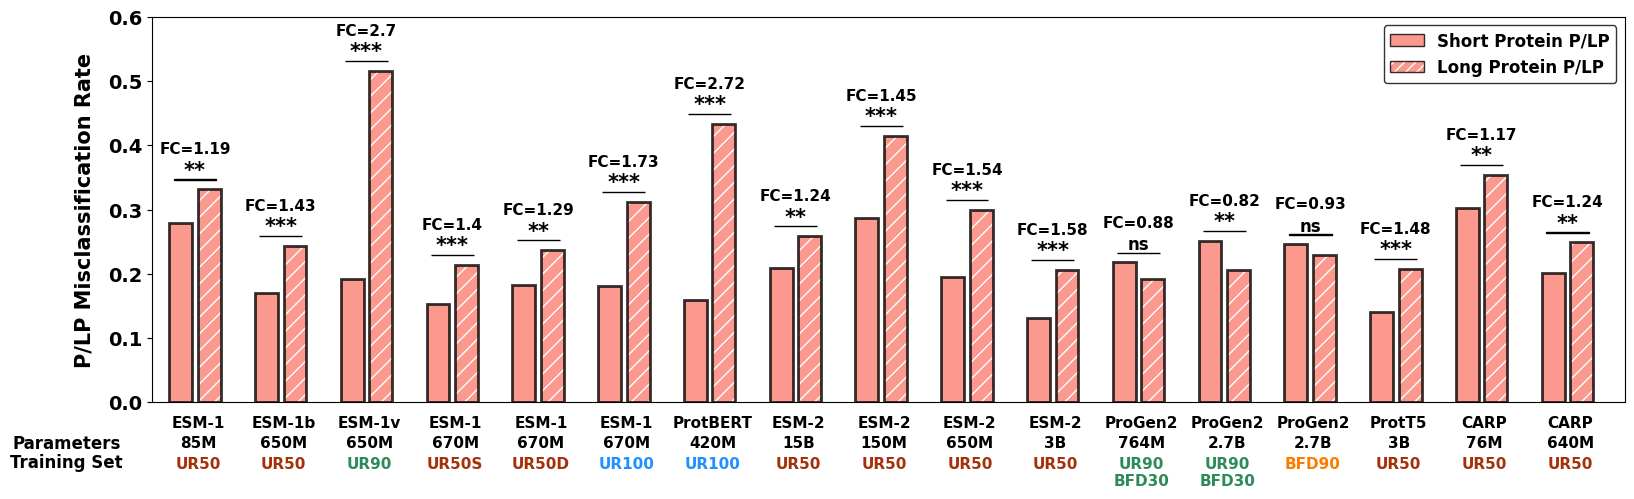

In [28]:
x = []
x_counter = 0
y = []
fc_list = []
stars_list = []
y_pos_list = []
model_list = []

p_list = []

for index, row in old_res_summary.iterrows():
    plp_rate_long = row["testing_PLP_misclass_rate_long"]
    plp_rate_short = row["testing_PLP_misclass_rate_short"]
    plp_chi_p_val = row["testing_chi_square_p_val_PLP"]
    
    
    total_accuracy = row["training_accuracy"]
    
    if total_accuracy < 0.75:
        continue
        
    p_list.append(plp_chi_p_val)
    
    stars_list.append(p_val_to_stars(plp_chi_p_val))
    model = row["model"]
    
    model_list.append(model)
    
    fc = plp_rate_long / plp_rate_short
    fc_list.append(fc)
    
    x.append(x_counter)
    y.append(plp_rate_short)
    
    x_counter += 1
    x.append(x_counter)
    y.append(plp_rate_long)
    
    x_counter += 2
    
    y_pos_list.append(max(plp_rate_long, plp_rate_short))
    
# plot_df_a = pd.DataFrame()


model_list_revisions = [
    "progen2_medium", 
    "progen2_large", 
    "progen2_bfd", 
    "prott5_xl", 
    "carp_38M", 
    "carp_76M", 
    "carp_640M"
]

for m in model_list_revisions:
    info = model_to_plp_error_info[m]
    density_data = model_to_density_plot_data[m]
    
    total_acc = density_data["max_acc"]
    if total_acc < 0.75:
        continue
    
    misclass_rate_short = info["misclass_rate_short"]
    misclass_rate_long = info["misclass_rate_long"]
    fc = info["fc"]
    
    model_list.append(m)
    
    fc_list.append(fc)
    stars_list.append(p_val_to_stars(info["chi_p"]))
    
    p_list.append(info["chi_p"])
    
    y_pos_list.append(max(misclass_rate_long, misclass_rate_short))
    
    x.append(x_counter)
    y.append(misclass_rate_short)
    x_counter += 1
    x.append(x_counter)
    y.append(misclass_rate_long)
    x_counter += 2
    
    

    

hatch_list = ["", "//"] * len(fc_list)
    
fig, ax = plt.subplots(figsize = (19,5))
ax.bar(x, y, color = "salmon", hatch =hatch_list, edgecolor = "black", linewidth = 2, zorder=100, alpha = 0.8)

patches = ax.patches
for patch, hatch in zip(patches, hatch_list):
    patch.set_hatch(hatch)
    patch._hatch_color = mcolors.to_rgba("white")
    
    
ax.tick_params(
    axis='x',          
    which='both',      
    bottom=False,      
    top=False,         
    labelbottom=False
) 

# adding bars, fc, and stars

for i, m in enumerate(model_list):
    
    
    x_pos = (i + 0.25) * 3
    
    ds_str =  model_to_dataset_str[m]
    
    ds_color = ur_50_color
    
    if "UR90" in ds_str:
        ds_color = ur_90_color
    elif "BFD" in ds_str:
        ds_color = bfd_color
    elif "UR100" in ds_str:
        ds_color = ur_100_color
    
    ax.text(x_pos-0.15, -0.04, model_to_base_str_c[m], horizontalalignment = "center", fontweight = "bold", fontsize = 11)
    ax.text(x_pos-0.15, -0.085, model_to_dataset_str[m], horizontalalignment = "center", fontweight = "bold", fontsize = 11, verticalalignment = "top", color = ds_color)
    ax.text(x_pos-0.15, -0.052, model_to_params_str[m], horizontalalignment = "center", fontweight = "bold", fontsize = 11, verticalalignment = "top")
    
    y_pos = y_pos_list[i]
    
    fc_val = fc_list[i]
    
    p_val_stars = stars_list[i]
    
    rect = mpatches.Rectangle((x_pos-1, y_pos + 0.015), 1.5, 0.0005, clip_on = False, color = "black")
    ax.add_patch(rect)
    
    
    p_fs = 15
    if p_val_stars == "ns":
        p_fs = 12
    
    ax.text(x_pos-0.25, y_pos + 0.02, p_val_stars,fontsize = p_fs, horizontalalignment = "center", fontweight= "bold")
    
    fc_str = "FC=" + str(round(fc_val, 2))
    ax.text(x_pos-0.25, y_pos + 0.055, fc_str, horizontalalignment = "center", fontsize = 11, fontweight= "bold")

    
ax.set_ylim(top = 0.6)
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold", fontsize = 14)

ax.set_xlim(left = -1, right = (len(model_list) * 3) - 0.5)

patch0 = mpatches.Patch(color = "salmon", edgecolor = "black", linewidth = 1, alpha = 0.8, label='Short Protein P/LP')
patch0.set_edgecolor("black")

patch1 = mpatches.Patch(color = "salmon", edgecolor = "black", linewidth = 1, alpha = 0.8, label='Long Protein P/LP')
patch1.set_hatch("///")
patch1.set_edgecolor("black")
patch1._hatch_color = mcolors.to_rgba("white")

ax.legend(handles=[patch0, patch1], loc = "upper right", prop = {"weight" : "bold", "size" : 12}, edgecolor = "black")
ax.set_ylabel("P/LP Misclassification Rate", fontweight = "bold", fontsize = 15, labelpad = 10)

ax.text(-4, -0.05, "Parameters", horizontalalignment = "center", fontweight = "bold", fontsize = 12, verticalalignment = "top")
ax.text(-4, -0.08, "Training Set", horizontalalignment = "center", fontweight = "bold", fontsize = 12, verticalalignment = "top")
    
# 
# for i , val in enumerate(np.arange(0.5,(3*len(needed_models)),3)):
#     ax.text(val , -0.04, model_to_base_string[needed_models[i]], horizontalalignment = "center", fontweight = "bold")
#     ax.text(val , -0.1, model_to_dataset_string[needed_models[i]], horizontalalignment = "center", fontweight = "bold", color = dataset_to_color[model_to_dataset_string[needed_models[i]]])
#     ax.text(val , -0.07, model_to_params_string[needed_models[i]], horizontalalignment = "center", fontweight = "bold")
#     rect = mpatches.Rectangle((val-0.75, y_bar_pos_list[i]), 1.5, 0.0005, clip_on = False, color = "black")
#     ax.add_patch(rect)
#     ax.text(val, y_bar_pos_list[i] + 0.005, star_list[i], fontweight = "bold", horizontalalignment = "center", fontsize = 13)
#     ax.text(val, y_bar_pos_list[i] + 0.04, "$\mathbf{FC=" + str(round(fc_list[i], 2)) + "}$", fontweight = "bold", horizontalalignment = "center",  fontsize = 9)
    

In [29]:
print(len(y), len(fc_list), len(p_list), len(model_list))

y_data_grouped = np.array(y).reshape(-1,2)

y_data_short = y_data_grouped[:, 0]
y_data_long = y_data_grouped[:, 1]

data_to_save = {
    "model" : model_list,
    "misclassification_short" : y_data_short,
    "misclassification_long" : y_data_long,
    "fold_change" : fc_list,
    "p_value" : p_list
    
}

df_output_data = pd.DataFrame(data_to_save)
df_output_data["model"] = df_output_data["model"].apply(
    lambda x : model_to_display_name[x] if x in model_to_display_name.keys() else x
)


df_output_data.to_csv(data_output_path + "fig_5/data_5i.csv")

df_output_data

34 17 17 17


,model,misclassification_short,misclassification_long,fold_change,p_value
0,ESM-1 (85M),0.279154,0.331522,1.187594,6.152491e-03
1,ESM-1b (650M),0.170393,0.243478,1.428924,9.832501e-06
2,ESM-1v (650M),0.191541,0.516304,2.695532,2.575981e-65
3,ESM-1 UR50 (670M),0.152870,0.214130,1.400735,1.095222e-04
4,ESM-1 UR50D (670M),0.183082,0.236957,1.294267,1.328245e-03
5,ESM-1 UR100 (670M),0.180665,0.311957,1.726716,3.858901e-14
6,ProtBERT,0.159517,0.433696,2.718812,3.479970e-52
7,ESM-2 (15B),0.209063,0.258696,1.237403,4.611942e-03
8,ESM-2 (150M),0.286405,0.415217,1.449757,3.962235e-11
9,ESM-2 (650M),0.194562,0.300000,1.541925,1.709909e-09


In [30]:
model_to_blb_error_info.keys()

dict_keys(['progen2_medium', 'progen2_large', 'progen2_bfd', 'prott5_xl', 'carp_38M', 'carp_76M', 'carp_640M'])

ESM-1 (85M) 1.072472999169205 0.1790607711898286
ESM-1b (650M) 1.1291738348451679 0.0545582122801695
ESM-1v (650M) 1.5171909355273425 2.3026313067759924e-15
ESM-1 UR50 (670M) 1.091404033433019 0.1697552517356441
ESM-1 UR50D (670M) 1.1543299419759956 0.023012964720034
ESM-1 UR100 (670M) 1.176400900367255 0.0017184835876542
ProtBERT 1.3967391304347825 1.0075022076583296e-10
ESM-2 (15B) 1.0604703435319378 0.3263861361313709
ESM-2 (150M) 1.230436309233024 6.362385209324518e-05
ESM-2 (650M) 1.2780909722758516 3.5562793809707355e-05
ESM-2 (3B) 1.0851979498055848 0.1780959689439436


/tmp/ipykernel_1962772/2294288275.py:145: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold", fontsize = 14)
/tmp/ipykernel_1962772/2294288275.py:149: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  patch0 = mpatches.Patch(color = "powderblue", edgecolor = "black", linewidth = 1, alpha = 0.8, label='Short Protein')
/tmp/ipykernel_1962772/2294288275.py:152: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  patch1 = mpatches.Patch(color = "powderblue", edgecolor = "black", linewidth = 1, alpha = 0.8, label='Long Protein')


Text(-4, -0.08, 'Training Set')

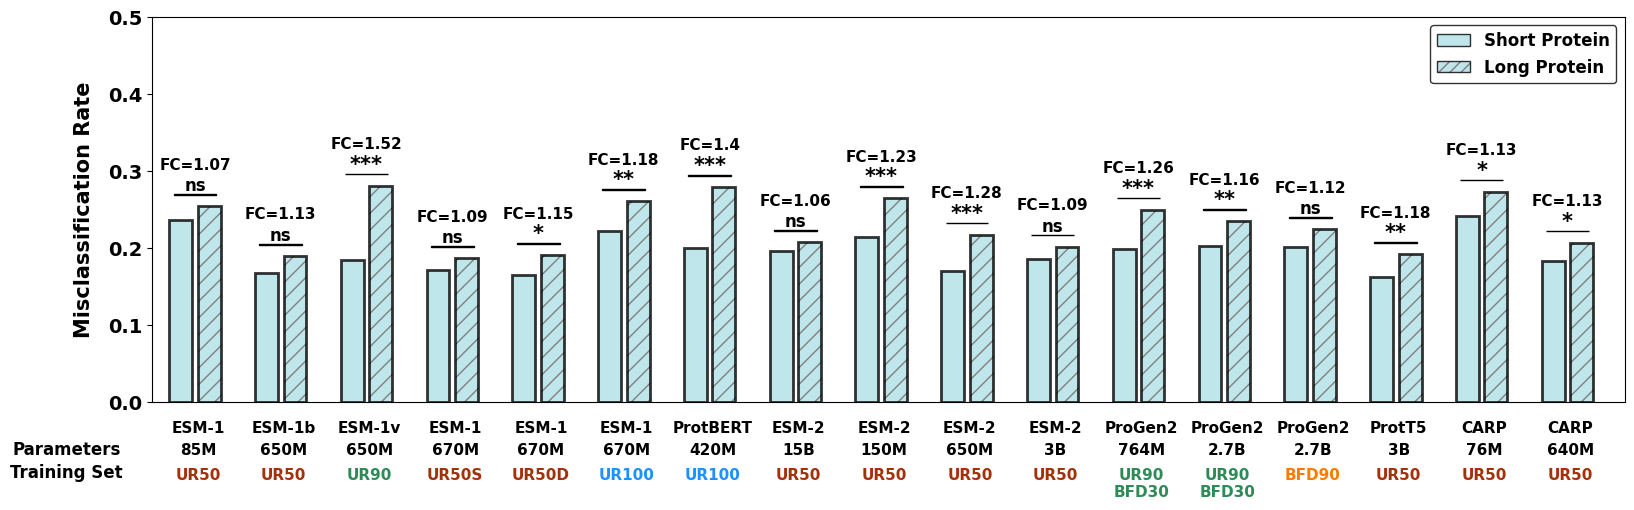

In [31]:

x = []
x_counter = 0
y = []
fc_list = []
stars_list = []
y_pos_list = []
model_list = []
p_list = []

for index, row in old_res_summary.iterrows():
    
    m = row["model"]
    k1 = (row["testing_BLB_misclass_rate_short"] + row["testing_PLP_misclass_rate_short"]) / 2
    k2 = (row["testing_BLB_misclass_rate_long"] + row["testing_PLP_misclass_rate_long"]) / 2
    
    
    combined_chi_p_val = row["testing_chi_square_p_val_combined"]
    total_accuracy = row["training_accuracy"]
    
    if total_accuracy < 0.75:
        continue
        
    p_list.append(combined_chi_p_val)
    
    fc = k2 / k1
    
    print(row["model"], fc, combined_chi_p_val)

    model_list.append(m)
    
    fc_list.append(fc)
    stars_list.append(p_val_to_stars(combined_chi_p_val))
    
    y_pos_list.append(max(k1, k2))
    
    x.append(x_counter)
    y.append(k1)
    x_counter += 1
    x.append(x_counter)
    y.append(k2)
    x_counter += 2
    
model_list_revisions = [
    "progen2_medium", 
    "progen2_large", 
    "progen2_bfd", 
    "prott5_xl", 
    "carp_38M", 
    "carp_76M", 
    "carp_640M"
]

for m in model_list_revisions:
    info = model_to_combined_error_info[m]
    density_data = model_to_density_plot_data[m]
    
    total_acc = density_data["max_acc"]
    if total_acc < 0.75:
        continue
    
    misclass_rate_short = info["misclass_rate_short"]
    misclass_rate_long = info["misclass_rate_long"]
    fc = info["fc"]
    
    model_list.append(m)
    
    fc_list.append(fc)
    stars_list.append(p_val_to_stars(info["chi_p"]))
    
    p_list.append(info["chi_p"])
    
    y_pos_list.append(max(misclass_rate_long, misclass_rate_short))
    
    x.append(x_counter)
    y.append(misclass_rate_short)
    x_counter += 1
    x.append(x_counter)
    y.append(misclass_rate_long)
    x_counter += 2
    
    
hatch_list = ["", "//"] * len(fc_list)
    
fig, ax = plt.subplots(figsize = (19,5))

ax.bar(x, y, color = "powderblue", hatch =hatch_list, edgecolor = "black", linewidth = 2, zorder=100, alpha = 0.8)

patches = ax.patches
for patch, hatch in zip(patches, hatch_list):
    patch.set_hatch(hatch)
    patch._hatch_color = mcolors.to_rgba("gray")
    
    
ax.tick_params(
    axis='x',          
    which='both',      
    bottom=False,      
    top=False,         
    labelbottom=False
) 

# adding bars, fc, and stars

for i, m in enumerate(model_list):
    
    
    x_pos = (i + 0.25) * 3
    
    ds_str =  model_to_dataset_str[m]
    
    ds_color = ur_50_color
    
    if "UR90" in ds_str:
        ds_color = ur_90_color
    elif "BFD" in ds_str:
        ds_color = bfd_color
    elif "UR100" in ds_str:
        ds_color = ur_100_color
    
    ax.text(x_pos-0.15, -0.04, model_to_base_str_c[m], horizontalalignment = "center", fontweight = "bold", fontsize = 11)
    ax.text(x_pos-0.15, -0.085, model_to_dataset_str[m], horizontalalignment = "center", fontweight = "bold", fontsize = 11, verticalalignment = "top", color = ds_color)
    ax.text(x_pos-0.15, -0.052, model_to_params_str[m], horizontalalignment = "center", fontweight = "bold", fontsize = 11, verticalalignment = "top")
    
    y_pos = y_pos_list[i]
    
    fc_val = fc_list[i]
    
    p_val_stars = stars_list[i]
    
    rect = mpatches.Rectangle((x_pos-1, y_pos + 0.015), 1.5, 0.0005, clip_on = False, color = "black")
    ax.add_patch(rect)
    
    
    p_fs = 15
    if p_val_stars == "ns":
        p_fs = 12
    
    ax.text(x_pos-0.25, y_pos + 0.02, p_val_stars,fontsize = p_fs, horizontalalignment = "center", fontweight= "bold")
    
    fc_str = "FC=" + str(round(fc_val, 2))
    ax.text(x_pos-0.25, y_pos + 0.048, fc_str, horizontalalignment = "center", fontsize = 11, fontweight= "bold")

    
ax.set_ylim(top = 0.5)
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold", fontsize = 14)

ax.set_xlim(left = -1, right = (len(model_list) * 3) - 0.5)

patch0 = mpatches.Patch(color = "powderblue", edgecolor = "black", linewidth = 1, alpha = 0.8, label='Short Protein')
patch0.set_edgecolor("black")

patch1 = mpatches.Patch(color = "powderblue", edgecolor = "black", linewidth = 1, alpha = 0.8, label='Long Protein')
patch1.set_hatch("///")
patch1.set_edgecolor("black")
patch1._hatch_color = mcolors.to_rgba("gray")

ax.legend(handles=[patch0, patch1], loc = "upper right", prop = {"weight" : "bold", "size" : 12}, edgecolor = "black")
ax.set_ylabel("Misclassification Rate", fontweight = "bold", fontsize = 15, labelpad = 10)

ax.text(-4, -0.05, "Parameters", horizontalalignment = "center", fontweight = "bold", fontsize = 12, verticalalignment = "top")
ax.text(-4, -0.08, "Training Set", horizontalalignment = "center", fontweight = "bold", fontsize = 12, verticalalignment = "top")
    


In [32]:

print(len(y), len(fc_list), len(p_list), len(model_list))

y_data_grouped = np.array(y).reshape(-1,2)

y_data_short = y_data_grouped[:, 0]
y_data_long = y_data_grouped[:, 1]

data_to_save = {
    "model" : model_list,
    "misclassification_short" : y_data_short,
    "misclassification_long" : y_data_long,
    "fold_change" : fc_list,
    "p_value" : p_list
    
}

df_output_data = pd.DataFrame(data_to_save)
df_output_data["model"] = df_output_data["model"].apply(
    lambda x : model_to_display_name[x] if x in model_to_display_name.keys() else x
)



df_output_data.to_csv(data_output_path + "fig_E6/data_E6c.csv")
df_output_data

34 17 17 17


,model,misclassification_short,misclassification_long,fold_change,p_value
0,ESM-1 (85M),0.237160,0.254348,1.072473,1.790608e-01
1,ESM-1b (650M),0.167976,0.189674,1.129174,5.455821e-02
2,ESM-1v (650M),0.185196,0.280978,1.517191,2.302631e-15
3,ESM-1 UR50 (670M),0.171299,0.186957,1.091404,1.697553e-01
4,ESM-1 UR50D (670M),0.165257,0.190761,1.154330,2.301296e-02
5,ESM-1 UR100 (670M),0.221752,0.260870,1.176401,1.718484e-03
6,ProtBERT,0.200000,0.279348,1.396739,1.007502e-10
7,ESM-2 (15B),0.195770,0.207609,1.060470,3.263861e-01
8,ESM-2 (150M),0.215106,0.264674,1.230436,6.362385e-05
9,ESM-2 (650M),0.170091,0.217391,1.278091,3.556279e-05


ESM-1 (85M) 0.9078106070803608 0.1780959689439436
ESM-1b (650M) 0.8206720088860682 0.1780959689439436
ESM-1v (650M) 0.2552511750881313 0.1780959689439436
ESM-1 UR50 (670M) 0.8421662974245361 0.1780959689439436
ESM-1 UR50D (670M) 0.9805550605844614 0.1780959689439436
ESM-1 UR100 (670M) 0.7981384307846074 0.1780959689439436
ProtBERT 0.519786432160804 0.1780959689439436
ESM-2 (15B) 0.8577598617909589 0.1780959689439436
ESM-2 (150M) 0.7936381074168795 0.1780959689439436
ESM-2 (650M) 0.9255818149016775 0.1780959689439436
ESM-2 (3B) 0.8180986454009176 0.1780959689439436


/tmp/ipykernel_1962772/2385964438.py:145: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold", fontsize = 14)
/tmp/ipykernel_1962772/2385964438.py:149: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  patch0 = mpatches.Patch(color = "darkseagreen", edgecolor = "black", linewidth = 1, alpha = 0.8, label='Short Protein')
/tmp/ipykernel_1962772/2385964438.py:152: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  patch1 = mpatches.Patch(color = "darkseagreen", edgecolor = "black", linewidth = 1, alpha = 0.8, label='Long Protein')


Text(-4, -0.08, 'Training Set')

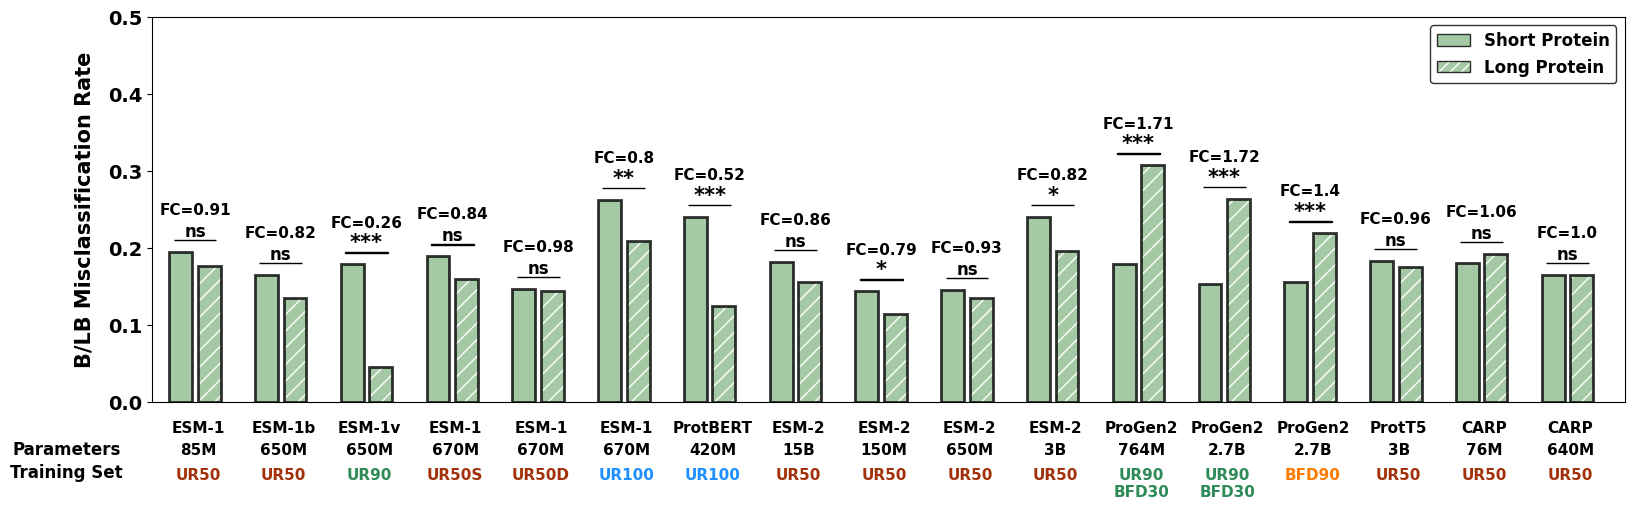

In [33]:

x = []
x_counter = 0
y = []
fc_list = []
stars_list = []
y_pos_list = []
model_list = []

p_list = []

for index, row in old_res_summary.iterrows():
    
    m = row["model"]
    k1 = row["testing_BLB_misclass_rate_short"] 
    k2 = row["testing_BLB_misclass_rate_long"]
    
    
    blb_chi_p_val = row["testing_chi_square_p_val_BLB"]
    total_accuracy = row["training_accuracy"]
    
    if total_accuracy < 0.75:
        continue
    
    fc = k2 / k1
    
    p_list.append(blb_chi_p_val)
    
    print(row["model"], fc, combined_chi_p_val)

    model_list.append(m)
    
    fc_list.append(fc)
    stars_list.append(p_val_to_stars(blb_chi_p_val))
    
    y_pos_list.append(max(k1, k2))
    
    x.append(x_counter)
    y.append(k1)
    x_counter += 1
    x.append(x_counter)
    y.append(k2)
    x_counter += 2
    
model_list_revisions = [
    "progen2_medium", 
    "progen2_large", 
    "progen2_bfd", 
    "prott5_xl", 
    "carp_38M", 
    "carp_76M", 
    "carp_640M"
]

for m in model_list_revisions:
    info = model_to_blb_error_info[m]
    density_data = model_to_density_plot_data[m]
    
    total_acc = density_data["max_acc"]
    if total_acc < 0.75:
        continue
    
    misclass_rate_short = info["misclass_rate_short"]
    misclass_rate_long = info["misclass_rate_long"]
    fc = info["fc"]
    
    model_list.append(m)
    fc_list.append(fc)
    stars_list.append(p_val_to_stars(info["chi_p"]))
    
    p_list.append(info["chi_p"])
    
    y_pos_list.append(max(misclass_rate_long, misclass_rate_short))
    
    x.append(x_counter)
    y.append(misclass_rate_short)
    x_counter += 1
    x.append(x_counter)
    y.append(misclass_rate_long)
    x_counter += 2
    
    
hatch_list = ["", "//"] * len(fc_list)
    
fig, ax = plt.subplots(figsize = (19,5))

ax.bar(x, y, color = "darkseagreen", hatch =hatch_list, edgecolor = "black", linewidth = 2, zorder=100, alpha = 0.8)

patches = ax.patches
for patch, hatch in zip(patches, hatch_list):
    patch.set_hatch(hatch)
    patch._hatch_color = mcolors.to_rgba("white")
    
    
ax.tick_params(
    axis='x',          
    which='both',      
    bottom=False,      
    top=False,         
    labelbottom=False
) 

# adding bars, fc, and stars

for i, m in enumerate(model_list):
    
    
    x_pos = (i + 0.25) * 3
    
    ds_str =  model_to_dataset_str[m]
    
    ds_color = ur_50_color
    
    if "UR90" in ds_str:
        ds_color = ur_90_color
    elif "BFD" in ds_str:
        ds_color = bfd_color
    elif "UR100" in ds_str:
        ds_color = ur_100_color
    
    ax.text(x_pos-0.15, -0.04, model_to_base_str_c[m], horizontalalignment = "center", fontweight = "bold", fontsize = 11)
    ax.text(x_pos-0.15, -0.085, model_to_dataset_str[m], horizontalalignment = "center", fontweight = "bold", fontsize = 11, verticalalignment = "top", color = ds_color)
    ax.text(x_pos-0.15, -0.052, model_to_params_str[m], horizontalalignment = "center", fontweight = "bold", fontsize = 11, verticalalignment = "top")
    
    y_pos = y_pos_list[i]
    
    fc_val = fc_list[i]
    
    p_val_stars = stars_list[i]
    
    rect = mpatches.Rectangle((x_pos-1, y_pos + 0.015), 1.5, 0.0005, clip_on = False, color = "black")
    ax.add_patch(rect)
    
    
    p_fs = 15
    if p_val_stars == "ns":
        p_fs = 12
    
    ax.text(x_pos-0.25, y_pos + 0.02, p_val_stars,fontsize = p_fs, horizontalalignment = "center", fontweight= "bold")
    
    fc_str = "FC=" + str(round(fc_val, 2))
    ax.text(x_pos-0.25, y_pos + 0.048, fc_str, horizontalalignment = "center", fontsize = 11, fontweight= "bold")

    
ax.set_ylim(top = 0.5)
ax.set_yticklabels(ax.get_yticklabels(), fontweight = "bold", fontsize = 14)

ax.set_xlim(left = -1, right = (len(model_list) * 3) - 0.5)

patch0 = mpatches.Patch(color = "darkseagreen", edgecolor = "black", linewidth = 1, alpha = 0.8, label='Short Protein')
patch0.set_edgecolor("black")

patch1 = mpatches.Patch(color = "darkseagreen", edgecolor = "black", linewidth = 1, alpha = 0.8, label='Long Protein')
patch1.set_hatch("///")
patch1.set_edgecolor("black")
patch1._hatch_color = mcolors.to_rgba("white")

ax.legend(handles=[patch0, patch1], loc = "upper right", prop = {"weight" : "bold", "size" : 12}, edgecolor = "black")
ax.set_ylabel("B/LB Misclassification Rate", fontweight = "bold", fontsize = 15, labelpad = 10)

ax.text(-4, -0.05, "Parameters", horizontalalignment = "center", fontweight = "bold", fontsize = 12, verticalalignment = "top")
ax.text(-4, -0.08, "Training Set", horizontalalignment = "center", fontweight = "bold", fontsize = 12, verticalalignment = "top")
    



In [34]:
# table data wrangling 


print(len(y), len(fc_list), len(p_list), len(model_list))

y_data_grouped = np.array(y).reshape(-1,2)

y_data_short = y_data_grouped[:, 0]
y_data_long = y_data_grouped[:, 1]

data_to_save = {
    "model" : model_list,
    "misclassification_short" : y_data_short,
    "misclassification_long" : y_data_long,
    "fold_change" : fc_list,
    "p_value" : p_list
    
}

df_output_data = pd.DataFrame(data_to_save)
df_output_data["model"] = df_output_data["model"].apply(
    lambda x : model_to_display_name[x] if x in model_to_display_name.keys() else x
)



df_output_data.to_csv(data_output_path + "fig_E6/data_E6d.csv")
df_output_data

34 17 17 17


,model,misclassification_short,misclassification_long,fold_change,p_value
0,ESM-1 (85M),0.195166,0.177174,0.907811,2.866273e-01
1,ESM-1b (650M),0.165559,0.135870,0.820672,5.258858e-02
2,ESM-1v (650M),0.178852,0.045652,0.255251,1.561237e-21
3,ESM-1 UR50 (670M),0.189728,0.159783,0.842166,6.493029e-02
4,ESM-1 UR50D (670M),0.147432,0.144565,0.980555,8.894263e-01
5,ESM-1 UR100 (670M),0.262840,0.209783,0.798138,3.110939e-03
6,ProtBERT,0.240483,0.125000,0.519786,2.968425e-12
7,ESM-2 (15B),0.182477,0.156522,0.857760,1.066326e-01
8,ESM-2 (150M),0.143807,0.114130,0.793638,3.909363e-02
9,ESM-2 (650M),0.145619,0.134783,0.925582,4.860830e-01


In [35]:
original_df = pd.read_csv(supp_table_path + "clinvar_misclassification_all_models_all_variants.csv", index_col = 0 )

df_model = original_df.loc[original_df["model"]=="ProtBERT"] # can be any model, just need the other columns to make it easier to add new models 


new_df_list = []

for wanted_model in model_to_boxplot_data_name_tracker.keys():
    all_score_dict = {}
    for n_list, s_list in zip(model_to_boxplot_data_name_tracker[wanted_model], model_to_boxplot_data[wanted_model]):
        d1 = dict(zip(n_list, s_list))
        all_score_dict = {**all_score_dict, **d1}
        
    c1 = copy.deepcopy(df_model)
    
    c1 = c1.drop(columns = ["model", "score"])
    
    c1["score"] = c1["full_name"].apply(lambda x : all_score_dict[x])
    c1["model"] = wanted_model

    new_df_list.append(c1)

    
new_df = pd.concat(new_df_list)

joined_df = pd.concat([original_df, new_df])

m_set = set(joined_df["model"])

name_dict = {}
for m in m_set:
    name_dict[m] = m 

model_name_converter = {
    "ProtBERT" : "ProtBERT UR100",
    "progen2_medium" : "ProGen2 (764M) UR90 BFD30",
    "progen2_large" : "ProGen2 (2.7B) UR90 BFD30",
    "progen2_bfd" : "ProGen2 (2.7B) BFD90",
    "protbert_bfd" : "ProtBERT BFD100",
    "prott5_xl" : "ProtT5-XL",
    "carp_38M" : "CARP (38M)",
    "carp_640M" : "CARP (640M)",
    "carp_76M" : "CARP (76M)"
}

for k, v in model_name_converter.items():
    name_dict[k] = v

joined_df["model"] = joined_df["model"].apply(lambda x : name_dict[x])

for m, sub_df in joined_df.groupby("model"):
    print(m, len(sub_df))
    
joined_df.to_csv(supp_table_path + "revisions/r_clinvar_misclassification_all_models_all_variants.csv", index = False)


CARP (38M) 15435
CARP (640M) 15435
CARP (76M) 15435
ESM-1 (43M) 15435
ESM-1 (85M) 15435
ESM-1 UR100 (670M) 15435
ESM-1 UR50 (670M) 15435
ESM-1 UR50D (670M) 15435
ESM-1b (650M) 15435
ESM-1v (650M) 15435
ESM-2 (150M) 15435
ESM-2 (15B) 15435
ESM-2 (35M) 15435
ESM-2 (3B) 15435
ESM-2 (650M) 15435
ESM-2 (8M) 15435
ProGen2 (2.7B) BFD90 15435
ProGen2 (2.7B) UR90 BFD30 15435
ProGen2 (764M) UR90 BFD30 15435
ProtBERT UR100 15435
ProtT5-XL 15435


In [36]:
original_df = pd.read_csv(supp_table_path + "long_clinvar_classification_summary_stats.csv", index_col = "model").drop(columns = "Unnamed: 0")

original_df = original_df.drop(columns = ["training_PLP_misclass_rate", "training_BLB_misclass_rate"])



model_list_revisions = [
    "progen2_medium", 
    "progen2_large", 
    "progen2_bfd", 
    "protbert_bfd", 
    "prott5_xl", 
    "carp_38M", 
    "carp_76M", 
    "carp_640M"
]

new_df = {}

for m in model_list_revisions:
    density_data = model_to_density_plot_data[m]
    
    training_accuracy = density_data["max_acc"]
    t_theta = density_data["argmax_acc"]
    
    
    testing_PLP_misclass_rate_long = model_to_plp_error_info[m]["misclass_rate_long"]
    testing_PLP_misclass_rate_short = model_to_plp_error_info[m]["misclass_rate_short"]
    testing_chi_square_p_val_PLP = model_to_plp_error_info[m]["chi_p"]
    plp_fc = model_to_plp_error_info[m]["fc"]
    
    testing_BLB_misclass_rate_long = model_to_blb_error_info[m]["misclass_rate_long"]
    testing_BLB_misclass_rate_short = model_to_blb_error_info[m]["misclass_rate_short"]
    testing_chi_square_p_val_BLB = model_to_blb_error_info[m]["chi_p"]
    blb_fc = model_to_blb_error_info[m]["fc"]
    
    testing_chi_square_p_val_combined = model_to_combined_error_info[m]["chi_p"] 
    fc_combined = model_to_combined_error_info[m]["fc"] 
    
    
    d1 = {
        "training_accuracy" : training_accuracy,
        "t_theta": t_theta,
        "testing_PLP_misclass_rate_long" : testing_PLP_misclass_rate_long,
        "testing_PLP_misclass_rate_short": testing_PLP_misclass_rate_short,
        "testing_BLB_misclass_rate_long":testing_BLB_misclass_rate_long,
        "testing_BLB_misclass_rate_short":testing_BLB_misclass_rate_short,
        "testing_chi_square_p_val_PLP":testing_chi_square_p_val_PLP,
        "testing_chi_square_p_val_BLB":testing_chi_square_p_val_BLB,
        "testing_chi_square_p_val_combined":testing_chi_square_p_val_combined,
        "testing_fc_BLB":blb_fc,
        "testing_fc_PLP":plp_fc,
        "testing_fc_combined":fc_combined
    }
    
    new_df[m] = d1
    

    
new_df = pd.DataFrame(new_df).T
combined = pd.concat([new_df, original_df]) 

combined["model"] = combined.index.values
combined["model"] = combined["model"].apply(lambda x : name_dict[x])
combined = combined.set_index("model")
combined.to_csv(supp_table_path + "revisions/r_long_clinvar_classification_summary_stats.csv")

KeyError: 'protbert_bfd'